# RNA Atlas (GSE138734) — exploratory analysis + LeafletFA (no-batch)

**Dataset:** primary cell-type bulk RNA-seq — 160 cell types, 23 organ systems. Excludes bulk mixed
tissues and cell lines. Aligned to GRCh38 / Gencode v45.

**Sample hierarchy — read this before interpreting any plot:**
2,228 **SRR runs** → 316 **GSM libraries** (2 per cell type) → 160 cell types.
The 2,228 rows are *sequencing runs*, 4–16 per library. **The replicate unit is the GSM**, not the
SRR (see §4b). Anything plotted per-SRR shows the same library 4–16 times over.

**This notebook:**
1. Load the filtered splice + GE AnnDatas (model-ready pair from WORKFLOW D9)
2. Attach cell metadata to GE (the filtered GE has an empty `obs` — metadata lives on splice)
3. Normalize GE (**TPM**, since this is bulk and we have `gene_length`) → marker expression
4. Marker sanity check (dotplot)
   **4b. Replicate structure + two-organ PCA + marker jitter plots ← start here**
5. PCA / UMAP on GE (all 23 organ systems — hard to read; §4b is the interpretable version)
6. Run **LeafletFA on all 2,228 samples at once (no minibatching)**

**⚠️ Run this on a GPU node** — LeafletFA needs one:
```bash
srun -p gpu --gres=gpu:1 --mem=200G -c 8 -t 8:00:00 --pty bash
conda activate LeafletSC
jupyter lab --no-browser --port 8888
```
(The GE sections, including §4b, run fine on CPU; only the LeafletFA section needs the GPU.)

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import torch

sc.settings.verbosity = 2
sc.set_figure_params(dpi=110, frameon=False)
plt.rcParams["figure.figsize"] = (5, 4)

print("torch CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "(CPU only)")

torch CUDA: True NVIDIA RTX PRO 6000 Blackwell Server Edition


## 1. Load the data

**Use the FULL GE object (63,241 genes) for expression analysis — NOT the 09b-filtered one.**

The filtered GE (`ge_adata_aligned_filtered_*`) has only **13,993** genes, because 09b restricts GE
to genes that have surviving junctions in the splice object. That drops most marker genes (CD14,
CD3D, EPCAM, ALB, MT-*, …). Crucially, that loss is **not** caused by our junction filter:

| Stage | Genes lost | Why |
|---|---|---|
| ATSE mapping | **47,364 (77%)** | gene has **no alternative splicing event at all** |
| our 09b filter (t=50) | 385 (2.7%) | junctions seen in <50 samples |

An ATSE requires ≥2 junctions **competing at a shared splice site**. Mitochondrial genes (no
introns), single-exon ncRNAs, and constitutively-spliced genes can *never* have one — at any filter
setting. Loosening the filter would recover **at most 385 genes**, not 47,364.

So: full GE for expression, filtered splice for LeafletFA. (LeafletFA training doesn't use GE at
all, so nothing about the model is affected.)

All objects are keyed by **SRR accession** in identical cell order (verified below).

In [2]:
WD = "/gpfs/commons/groups/knowles_lab/Karin/Leaflet-analysis-WD/RNA_ATLAS/GSE138734"
MODEL_INPUT = f"{WD}/MODEL_INPUT/20260709"
TAG = "filtered_minCells50_minJuncs500_2026-07-11"

# splice: the FILTERED / ATSE-regrouped object — this is the LeafletFA model input
splice = ad.read_h5ad(f"{MODEL_INPUT}/splice_adata_aligned_{TAG}.h5ad")

# GE: the FULL object (all 63,241 genes) — needed for markers / PCA.
# Do NOT use ge_adata_aligned_filtered_* here: it has only the 13,993 genes that carry
# splice junctions, and is missing most marker genes.
ge = ad.read_h5ad(f"{WD}/gene_expression/ge_adata_rna_atlas.h5ad")

print("splice:", splice.shape, "| layers:", list(splice.layers))
print("ge    :", ge.shape, "| layers:", list(ge.layers), " <- full gene set")
print("\nsplice.obs:", list(splice.obs.columns))
print("ge.obs   :", list(ge.obs.columns), "  <- empty; we fix this next")

splice: (2228, 128138) | layers: ['cell_by_cluster_matrix', 'cell_by_junction_matrix']
ge    : (2228, 63241) | layers: ['counts']  <- full gene set

splice.obs: ['cell_type', 'organ_system', 'gsm', 'sample_type']
ge.obs   : []   <- empty; we fix this next


## 2. Transfer metadata onto GE

The GE object has an empty `obs` (it was built straight from featureCounts). `05_build_ge_anndata.py`
was run with `--splice`, so its cell order already matches the splice object — but we **assert** it
rather than trust it, then copy the metadata across.

In [3]:
assert list(splice.obs_names) == list(ge.obs_names), "cell order differs — do NOT copy obs blindly!"
print("✓ cell order identical across splice and GE")

for col in ["cell_type", "organ_system", "gsm", "sample_type"]:
    ge.obs[col] = splice.obs[col].values

ge.obs["cell_type"] = ge.obs["cell_type"].astype("category")
ge.obs["organ_system"] = ge.obs["organ_system"].astype("category")

print(f"\n{ge.n_obs:,} samples | {ge.obs['cell_type'].nunique()} cell types | "
      f"{ge.obs['organ_system'].nunique()} organ systems | {ge.obs['gsm'].nunique()} GSMs")
display(ge.obs['organ_system'].value_counts().to_frame("n_samples").head(10))

✓ cell order identical across splice and GE

2,228 samples | 160 cell types | 23 organ systems | 316 GSMs


,n_samples
organ_system,
Central Nervous System,228
Cardiac System,184
Dermal System,180
Pulmonary System,168
Hematopoietic System,163
Female Reproductive System,136
Ocular System,128
Gastrointestinal System,125
Mesenchymal Stem System,96


## 3. Normalize GE — **TPM** (bulk-appropriate)

This is **bulk** RNA-seq, so gene length matters: longer genes accrue more fragments purely by
length. CPM/`normalize_total` (the single-cell default) does **not** correct for this — TPM does,
and we have `var['gene_length']` from featureCounts.

TPM: `rate = counts / gene_length` → `TPM = 1e6 * rate / sum(rate)` → then `log1p`.

> **Correction to the WORKFLOW D8 note.** D8 says *"a subset of samples (monocytes/NK/T cells) are
> Ribo-Zero total-RNA libraries with lower exonic assignment"*. That understates it: **half of all
> libraries are Ribo-Zero** — GSE138734 prepped every RNA sample as both a polyA **and** a total-RNA
> (Ribo-Zero Gold) library, so ~158 of the 316 GSMs are total RNA, one per cell type. See §4b.
> TPM normalizes for depth, but Ribo-Zero libraries genuinely carry more intronic / nascent signal,
> and that is a systematic effect on PSI, not a quirk of a few immune samples.

TPM row sums (should be 1e6): [1000000. 1000000. 1000000.]
log1p(TPM) range: 0.00 – 13.33


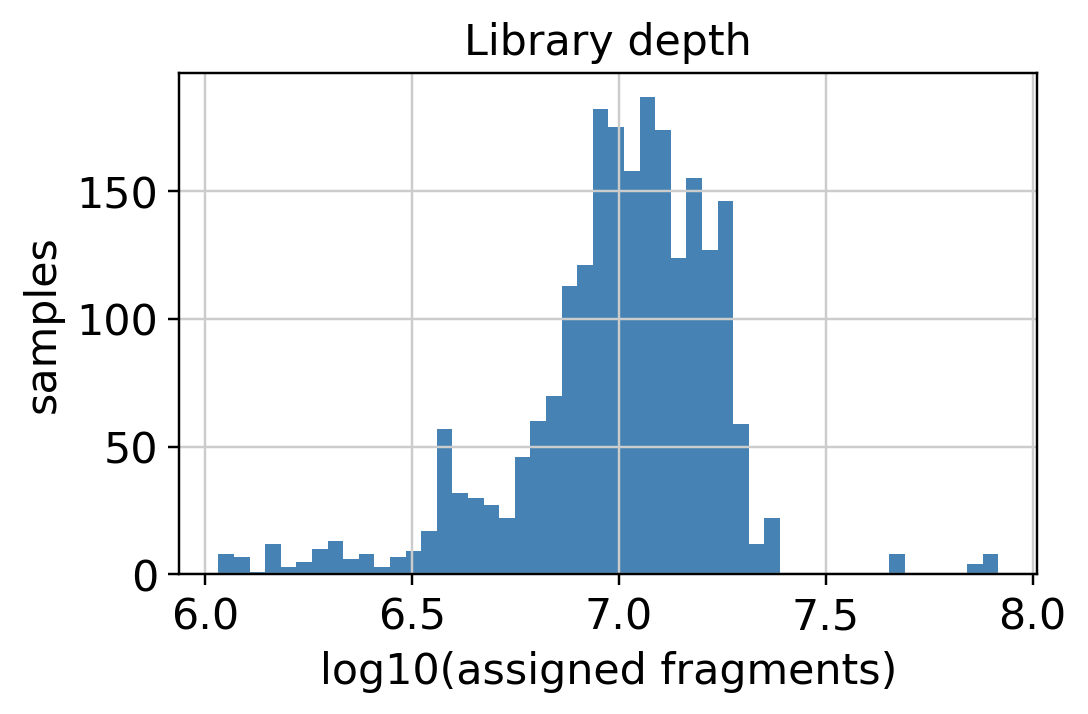

In [4]:
ge.layers["counts"] = ge.X.copy()  # keep raw fragment counts

counts = ge.layers["counts"]
counts = counts.toarray() if sp.issparse(counts) else np.asarray(counts)
lengths = ge.var["gene_length"].values.astype(float)
lengths[lengths <= 0] = np.nan

rate = counts / lengths[None, :]                      # length-normalize
rate = np.nan_to_num(rate, nan=0.0, posinf=0.0)
tpm = 1e6 * rate / np.maximum(rate.sum(axis=1, keepdims=True), 1e-12)

ge.layers["tpm"] = tpm.astype(np.float32)
ge.X = np.log1p(ge.layers["tpm"])                     # log1p(TPM) for PCA / plotting

print(f"TPM row sums (should be 1e6): {tpm.sum(1)[:3].round(0)}")
print(f"log1p(TPM) range: {ge.X.min():.2f} – {ge.X.max():.2f}")

# library depth per sample (assigned fragments) — note the spread across cell types
ge.obs["total_counts"] = counts.sum(1)
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(np.log10(ge.obs["total_counts"] + 1), bins=50, color="steelblue")
ax.set_xlabel("log10(assigned fragments)"); ax.set_ylabel("samples")
ax.set_title("Library depth"); plt.show()

In [5]:
ge.obs

,cell_type,organ_system,gsm,sample_type,total_counts
SRR10261826,Cardiac Fibroblast fetal atrial,Cardiac System,GSM4117821,cell type,7099413.0
SRR10261828,Cardiac Fibroblast fetal atrial,Cardiac System,GSM4117821,cell type,7284759.0
SRR10261827,Cardiac Fibroblast fetal atrial,Cardiac System,GSM4117821,cell type,7224621.0
SRR10261829,Cardiac Fibroblast fetal atrial,Cardiac System,GSM4117821,cell type,7014540.0
SRR10261830,Cardiac Fibroblast fetal atrial,Cardiac System,GSM4117821,cell type,7400376.0
...,...,...,...,...,...
SRR10262412,Amniotic Epithelial Cell,Placenta System,GSM4117863,cell type,4015891.0
SRR10262413,Amniotic Epithelial Cell,Placenta System,GSM4117863,cell type,3827463.0
SRR10262414,Amniotic Epithelial Cell,Placenta System,GSM4117863,cell type,8859261.0
SRR10262415,Villous Trophoblast,Placenta System,GSM4117864,cell type,8961223.0


## 4. Marker gene expression

Sanity check that the data behaves: canonical lineage markers should light up in the right
organ systems / cell types.

/gpfs/commons/home/kisaev/miniconda3/envs/LeafletSC/lib/python3.10/site-packages/anndata/utils.py:264: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`Example key collisions generated by the make_index_unique algorithm: ['SNORD116-1', 'SNORD116-2', 'SNORD116-3', 'SNORD116-4', 'SNORD116-5']
  warnings.warn(


markers found: {'Endothelial': 3, 'Fibroblast': 3, 'Smooth muscle': 3, 'Epithelial': 3, 'Keratinocyte': 2, 'Immune (pan)': 1, 'Monocyte': 2, 'T cell': 2, 'NK': 2, 'B cell': 2, 'Astrocyte/glia': 2, 'Cardiac': 2, 'Hepatocyte': 1, 'Melanocyte': 2}


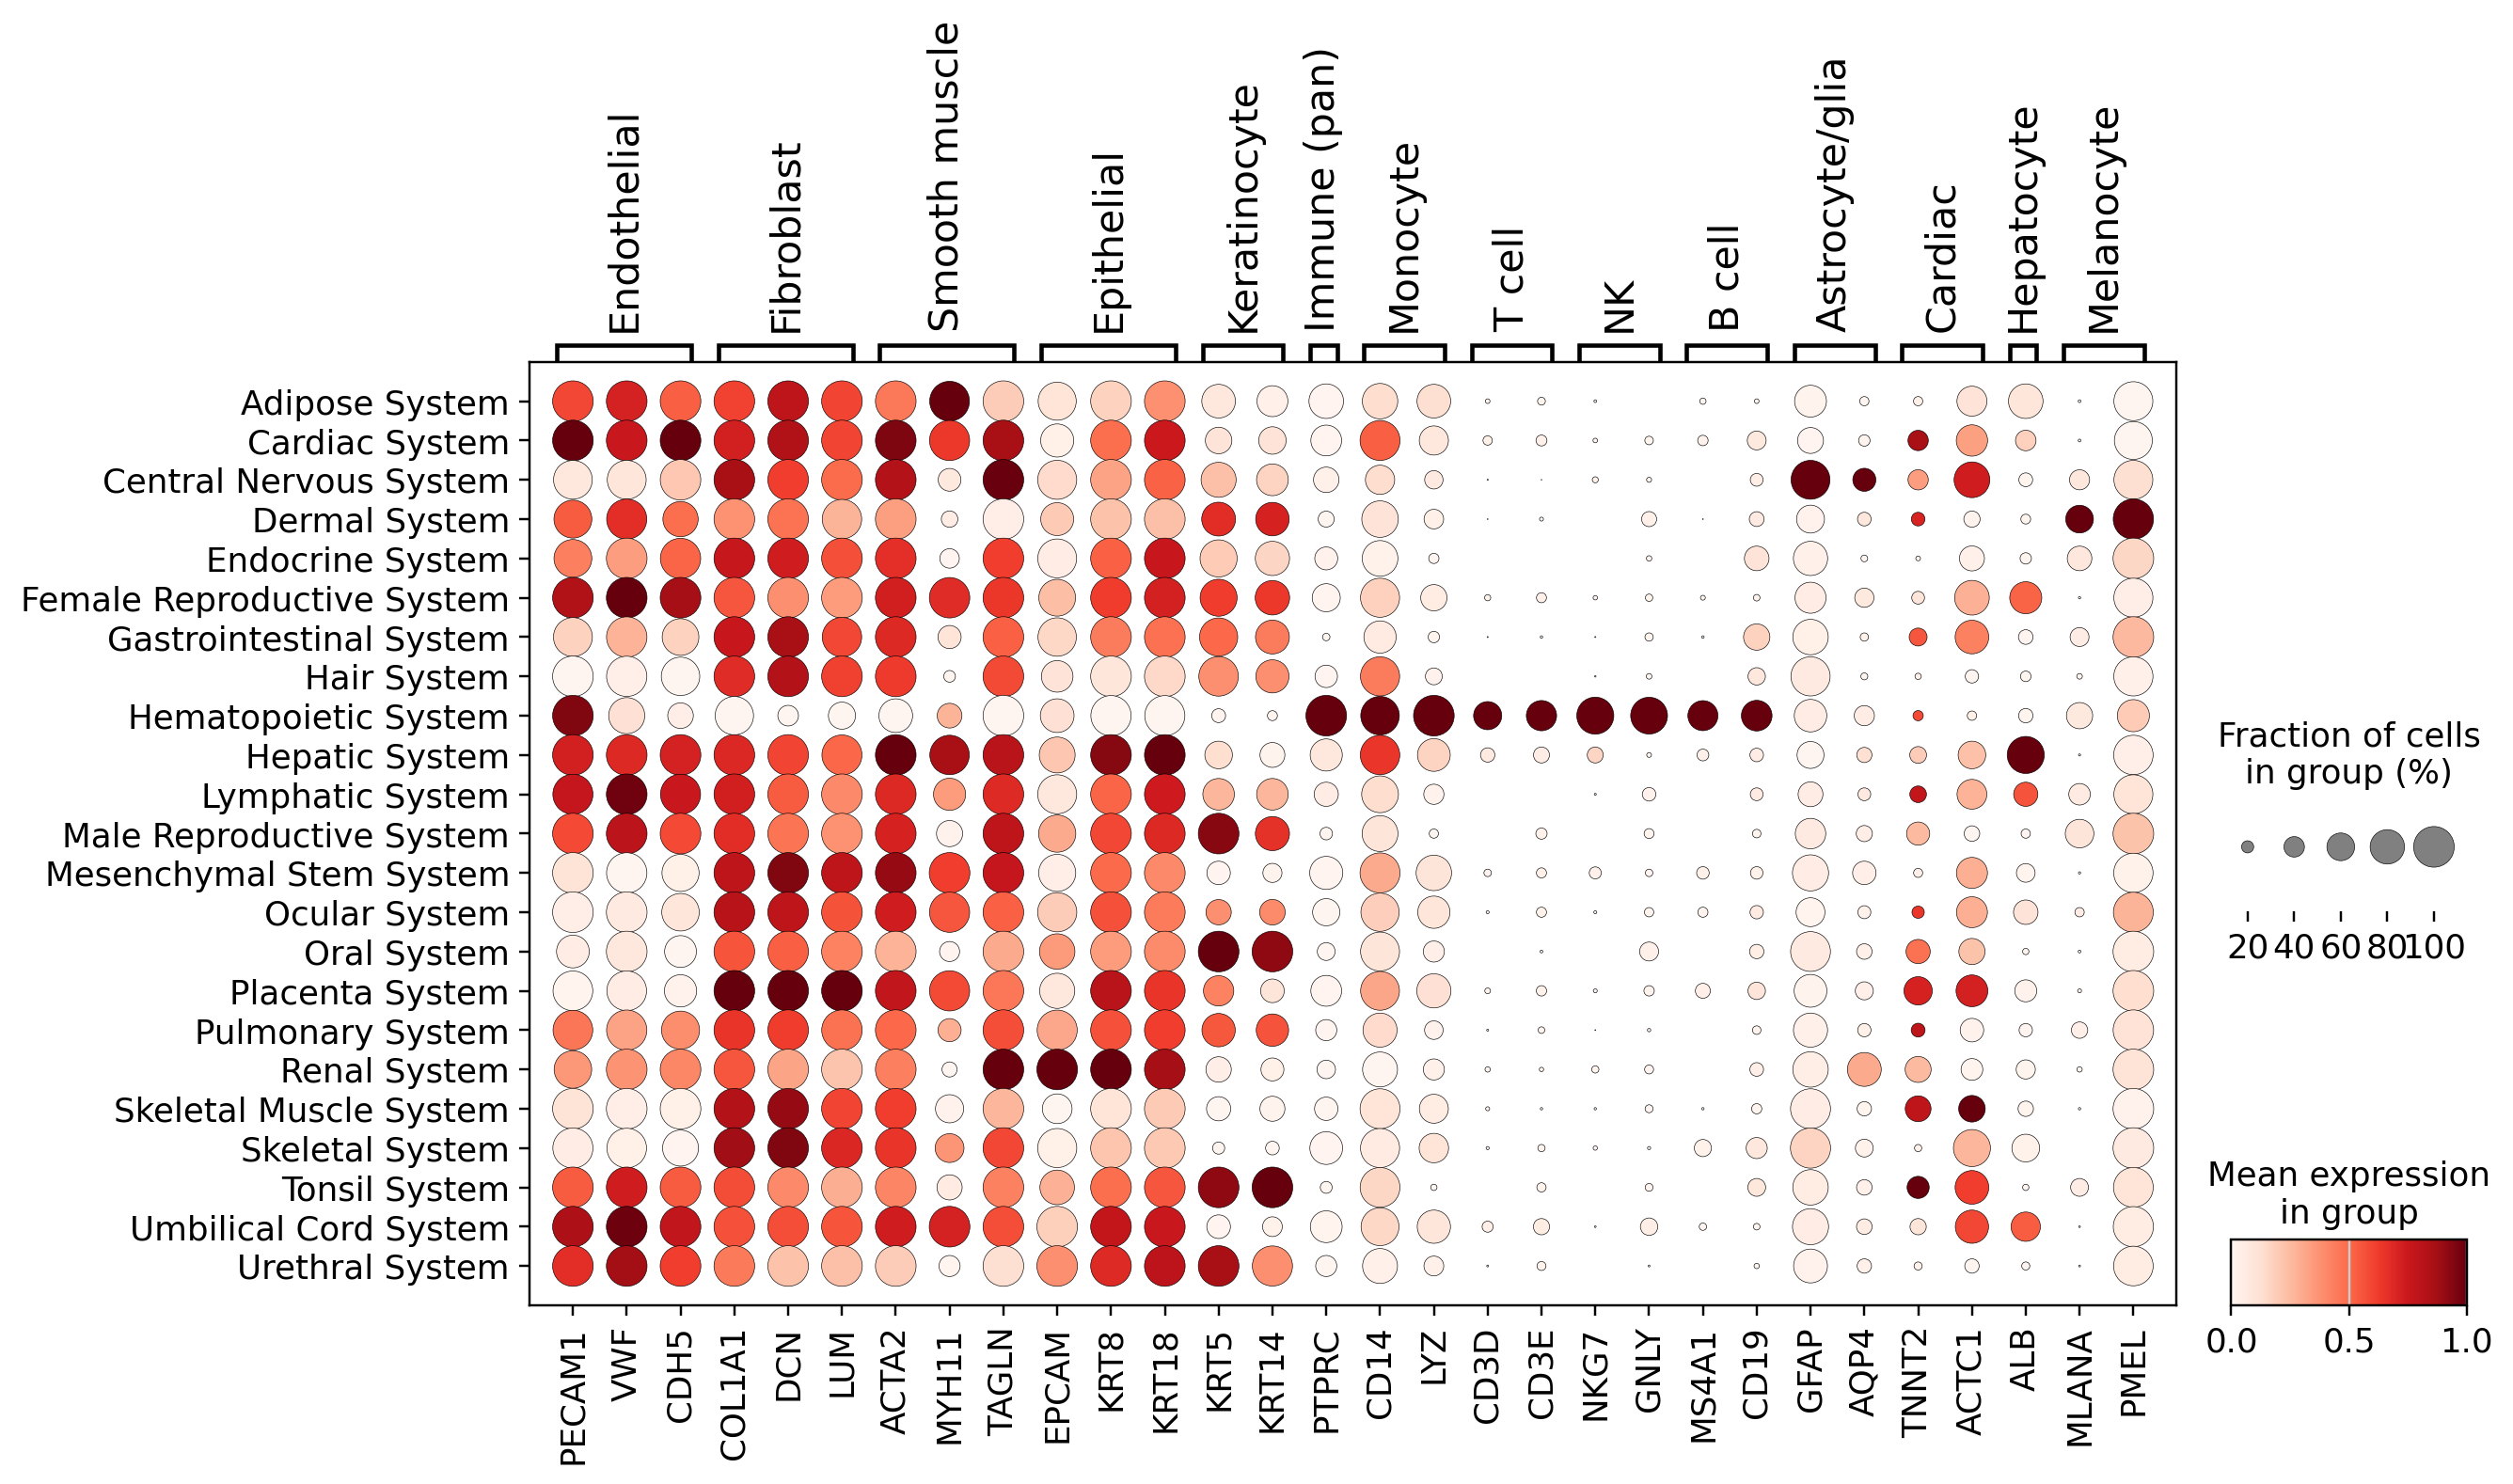

In [6]:
# GE var_names are versioned gene_ids → index by symbol for marker lookup
ge.var["gene_id"] = ge.var_names
ge.var_names = ge.var["gene_name"].astype(str).values
ge.var_names_make_unique()

MARKERS = {
    "Endothelial":   ["PECAM1", "VWF", "CDH5"],
    "Fibroblast":    ["COL1A1", "DCN", "LUM"],
    "Smooth muscle": ["ACTA2", "MYH11", "TAGLN"],
    "Epithelial":    ["EPCAM", "KRT8", "KRT18"],
    "Keratinocyte":  ["KRT5", "KRT14"],
    "Immune (pan)":  ["PTPRC"],
    "Monocyte":      ["CD14", "LYZ"],
    "T cell":        ["CD3D", "CD3E"],
    "NK":            ["NKG7", "GNLY"],
    "B cell":        ["MS4A1", "CD19"],
    "Astrocyte/glia":["GFAP", "AQP4"],
    "Cardiac":       ["TNNT2", "ACTC1"],
    "Hepatocyte":    ["ALB"],
    "Melanocyte":    ["MLANA", "PMEL"],
}
MARKERS = {k: [g for g in v if g in ge.var_names] for k, v in MARKERS.items()}
MARKERS = {k: v for k, v in MARKERS.items() if v}
print("markers found:", {k: len(v) for k, v in MARKERS.items()})

sc.pl.dotplot(ge, MARKERS, groupby="organ_system", standard_scale="var",
              figsize=(12, 6), show=True)

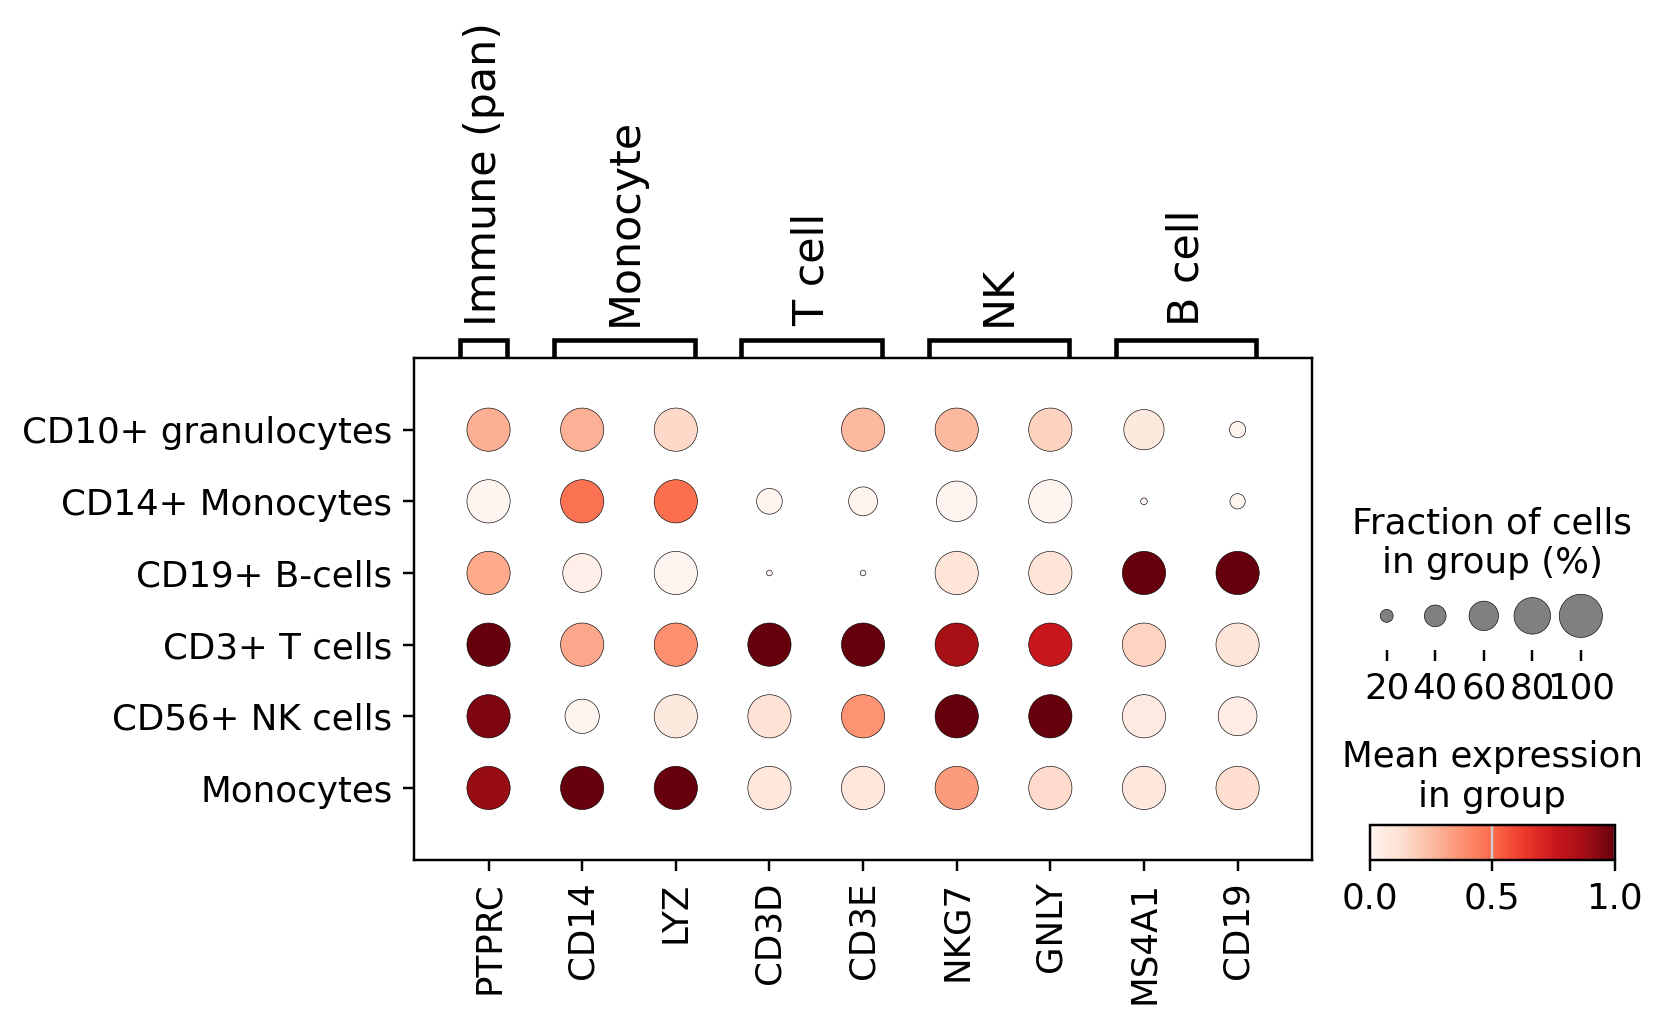

In [7]:
# Zoom in on the immune cell types (the ones with distinctive library chemistry)
immune = ["CD14+ Monocytes", "Monocytes", "CD3+ T cells", "CD56+ NK cells",
          "CD19+ B-cells", "CD10+ granulocytes"]
immune = [c for c in immune if c in set(ge.obs["cell_type"])]
sub = ge[ge.obs["cell_type"].isin(immune)].copy()
sub.obs["cell_type"] = sub.obs["cell_type"].cat.remove_unused_categories()

sc.pl.dotplot(sub, {k: MARKERS[k] for k in ["Immune (pan)", "Monocyte", "T cell", "NK", "B cell"]
                    if k in MARKERS},
              groupby="cell_type", standard_scale="var", figsize=(7, 3), show=True)

## 4b. Ground truth check: what is a sample, and what are the units?

The global UMAP/PCA in §5 is unreadable (23 colours, 2,228 points, a handful of outliers squashing
everything into one corner). Before trusting any of it, pin down what a row actually *is*.

### The sample hierarchy (verified against the GEO series matrix, not inferred)

GSE138734 took ~300 RNA samples and prepped **each one three ways**, as consecutive GSMs:

```
GSM4117198  RNAAtlas001_polyA_RNA  [RNA_AT001]   ~60M PE reads   ← we use this
GSM4117199  RNAAtlas001_sRNA       [RNA_AT001]                   ← not in our pipeline
GSM4117200  RNAAtlas001_total_RNA  [RNA_AT001]   ~125M PE reads  ← we use this
```

which is why our paired accessions sit **2 apart** (`GSM4117876`/`GSM4117878`). Our 316 GSMs are
**158 polyA + 158 total RNA + 0 small RNA**, spanning **160 RNA samples** (156 have both libraries,
4 have only one).

| unit | n | what it is |
|---|---|---|
| SRR | 2,228 | one sequencing **run** (lane); 4–16 per library |
| GSM | 316 | one **library** = one RNA sample × one protocol |
| **sample_id** | **160** | one **RNA sample** (`RNA_AT241`) — the biological unit |
| cell type | 160 | one RNA sample each |
| organ system | 23 | |

**Three consequences, and they are the whole point of this section:**

1. **The 2,228 rows are runs, not samples.** Runs of one library are re-sequencing of the *same*
   library — not independent observations. We collapse runs → library by **summing raw counts** and
   re-deriving TPM/PSI.

2. **The run count is confounded with protocol.** Total RNA was sequenced ~2× deeper (125M vs 60M),
   so it got more lanes: polyA libraries have 4 runs (142 of them) or 8 (16); total-RNA libraries
   have 8 (120), 16 (32), 11 (5) or 5 (1). At the SRR level that silently hands total-RNA libraries
   **~2–4× the ELBO weight** of polyA ones — i.e. the nascent-RNA-heavy protocol was over-weighted
   in every model trained on the 2,228-row object. Collapsing fixes this.

3. **There are no biological replicates.** The two GSMs of a cell type are the *same RNA* through
   two library preps. So "replicate" here means **protocol replicate**, and that is a *systematic*
   difference, not noise: Ribo-Zero total RNA retains nascent, unspliced pre-mRNA, which shifts PSI
   for the events LeafletFA models. The protocol panel below decides whether we train on all 316 or
   on one protocol.

### Units

featureCounts fragments → **TPM** (÷ gene length, rescale each library to 1e6) → **log2(TPM + 1)**.
TPM is within-sample relative abundance — "of every million transcripts in this library, how many
are this gene". Comparable across libraries for a given gene (what the jitter plots do) and
length-corrected, which CPM/`normalize_total` is not; this is bulk, so length matters.

In [8]:
# ── The replicate structure, spelled out ───────────────────────────────────────
struct = (ge.obs.groupby(["organ_system", "cell_type", "gsm"], observed=True)
                .size().rename("n_runs").reset_index())

print(f"{ge.n_obs:,} SRR runs  ->  {struct['gsm'].nunique()} GSM libraries  ->  "
      f"{struct['cell_type'].nunique()} cell types  ->  {struct['organ_system'].nunique()} organ systems")
print("runs per library      :", struct["n_runs"].describe()[["min", "50%", "max"]].astype(int).to_dict())
print("libraries per cell type:",
      struct.groupby("cell_type", observed=True).size().value_counts().sort_index().to_dict())

# ── Collapse runs -> library: sum raw fragment counts, then re-derive TPM ──────
# (summing counts is the right way to pool runs of one library; averaging TPMs is not)
raw = ge.layers["counts"]
raw = raw.toarray() if sp.issparse(raw) else np.asarray(raw)

gsm_key = ge.obs["gsm"].astype(str).values
gsms    = pd.unique(gsm_key)
row_of  = pd.Series(np.arange(len(gsms)), index=gsms).loc[gsm_key].values
S       = sp.csr_matrix((np.ones(ge.n_obs), (row_of, np.arange(ge.n_obs))),
                        shape=(len(gsms), ge.n_obs))          # library x run indicator
C_gsm   = S @ raw                                             # pooled fragment counts

lengths = ge.var["gene_length"].values.astype(float)
lengths[lengths <= 0] = np.nan

def to_tpm(C):
    """fragment counts -> TPM: length-normalise, then rescale each row to 1e6."""
    rate = np.nan_to_num(C / lengths[None, :], nan=0.0, posinf=0.0)
    return 1e6 * rate / np.maximum(rate.sum(1, keepdims=True), 1e-12)

tpm_gsm = to_tpm(C_gsm)

meta = (ge.obs.groupby("gsm", observed=True)
              .agg(cell_type=("cell_type", "first"), organ_system=("organ_system", "first"),
                   n_runs=("gsm", "size"), total_counts=("total_counts", "sum"))
              .loc[gsms])

ge_gsm = ad.AnnData(X=np.log2(tpm_gsm + 1).astype(np.float32), obs=meta, var=ge.var.copy())
ge_gsm.layers["tpm"] = tpm_gsm.astype(np.float32)     # raw TPM, for reporting real numbers
ge_gsm.obs["organ_system"] = ge_gsm.obs["organ_system"].astype("category")

print(f"\nlibrary-level object: {ge_gsm.shape}   X = log2(TPM + 1)   layers['tpm'] = TPM")
print(f"pooled depth per library: median {ge_gsm.obs.total_counts.median()/1e6:.0f}M fragments "
      f"(range {ge_gsm.obs.total_counts.min()/1e6:.0f}M–{ge_gsm.obs.total_counts.max()/1e6:.0f}M)")

2,228 SRR runs  ->  316 GSM libraries  ->  160 cell types  ->  23 organ systems
runs per library      : {'min': 4, '50%': 8, 'max': 16}
libraries per cell type: {1: 4, 2: 156}

library-level object: (316, 63241)   X = log2(TPM + 1)   layers['tpm'] = TPM
pooled depth per library: median 64M fragments (range 8M–644M)


parsed 921 GSMs from GEO: {'small RNA': 298, 'total RNA (Ribo-Zero)': 296, 'polyA': 295, 'other': 32}

OUR libraries by protocol: {'total RNA (Ribo-Zero)': 158, 'polyA': 158}
distinct RNA samples (sample_id): 160
libraries per RNA sample: {1: 4, 2: 156}

⇒ 158 polyA + 158 total RNA, over 160 RNA samples: 156 samples have BOTH libraries,
  4 have only one. A cell type's 'replicate' pair = polyA + total RNA of ONE RNA sample.
  n(independent biological samples) = n(cell types). There are NO biological replicates.

73 replication-dependent histone genes — expect ~0 in polyA, high in total RNA


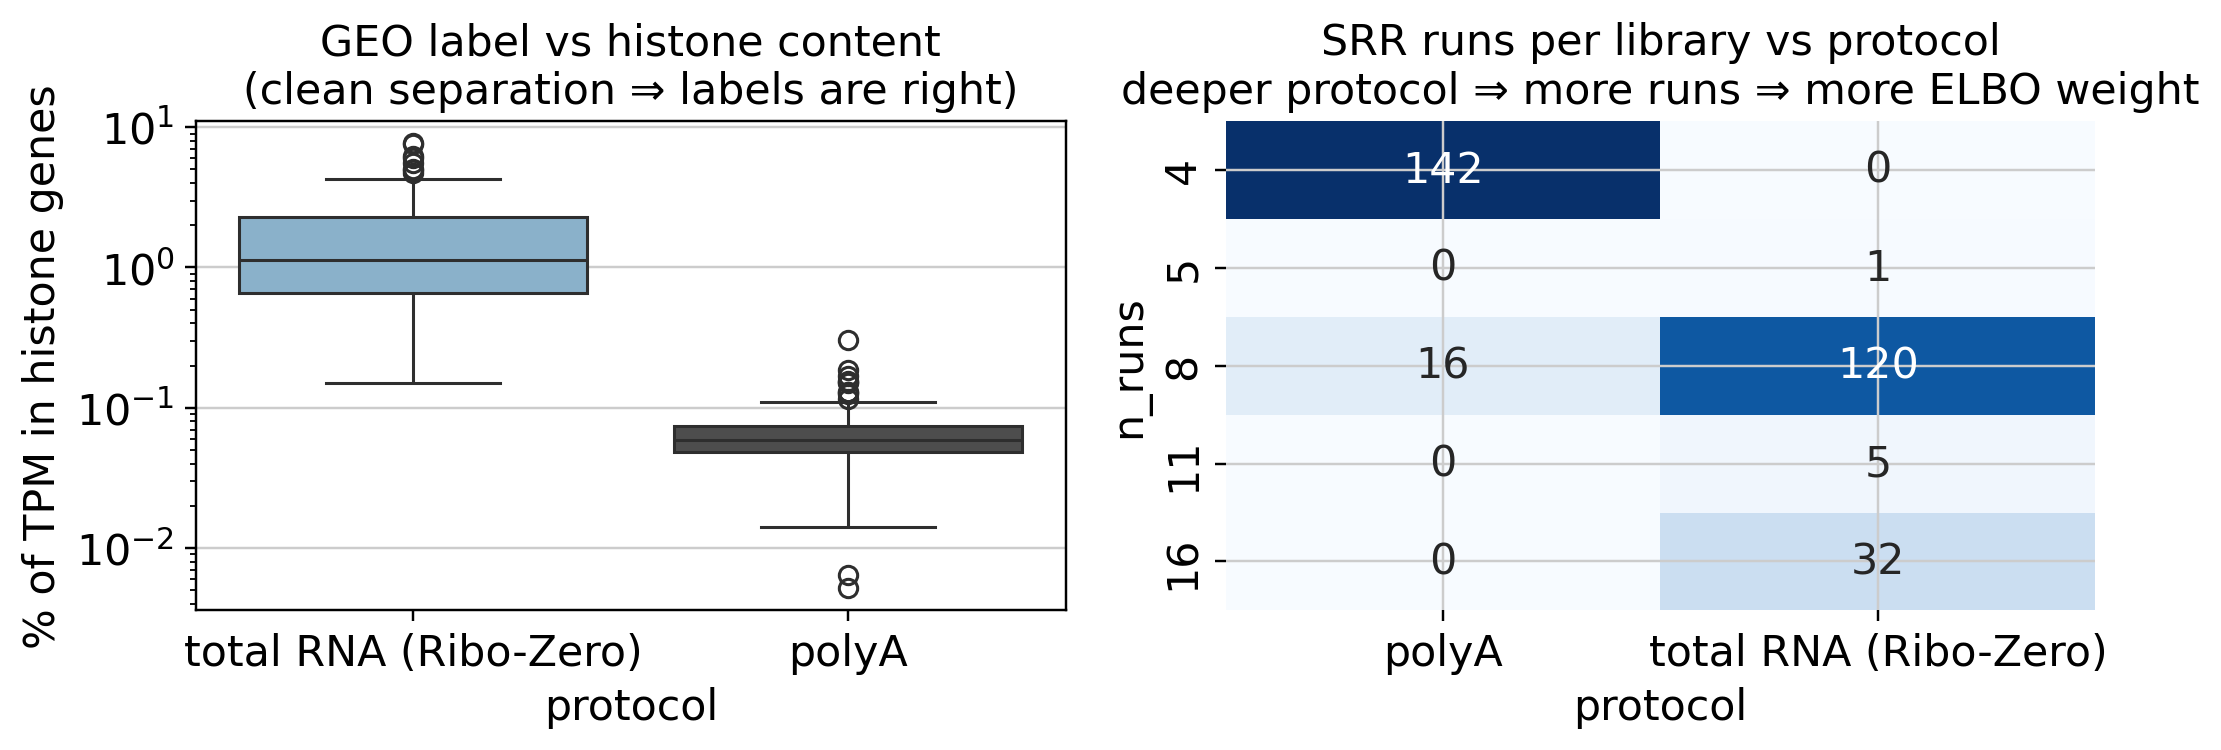

,count,50%,max
protocol,,,
polyA,158.0,0.059,0.304
total RNA (Ribo-Zero),158.0,1.133,7.669


In [9]:
# ── What ARE the 2 GSMs per cell type? Ground truth from GEO ──────────────────
# GSE138734 prepped every RNA sample THREE ways, as consecutive GSMs:
#     GSM4117198  RNAAtlas001_polyA_RNA  [RNA_AT001]   ~60M PE reads
#     GSM4117199  RNAAtlas001_sRNA       [RNA_AT001]   (small RNA — not in our pipeline)
#     GSM4117200  RNAAtlas001_total_RNA  [RNA_AT001]   ~125M PE reads (Ribo-Zero Gold)
# So the 2 GSMs of a cell type are the SAME RNA through two library preps — NOT two donors.
#
# Do NOT infer protocol from the GSM number (e.g. mod 3): the series is missing libraries
# (298 sRNA / 295 polyA / 296 total, not 300 each), so the triples have gaps and the phase
# shifts. Use the GEO labels. The series spans TWO platforms -> two matrix files, no combined one:
#
#   WD=/gpfs/commons/groups/knowles_lab/Karin/Leaflet-analysis-WD/RNA_ATLAS/GSE138734
#   for P in GPL18573 GPL20301; do
#     wget -qO- "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE138nnn/GSE138734/matrix/GSE138734-${P}_series_matrix.txt.gz" \
#       | zcat | grep -E '^!Sample_geo_accession|^!Sample_title'
#   done > $WD/gsm_titles.txt
import re

GSM_TITLES = f"{WD}/gsm_titles.txt"
assert os.path.exists(GSM_TITLES), f"missing {GSM_TITLES} — run the wget loop in the comment above"

# one block per platform, so each key appears twice — keep them all
blocks = {}
for line in open(GSM_TITLES):
    parts = [p.strip().strip('"') for p in line.rstrip("\n").split("\t")]
    blocks.setdefault(parts[0], []).append(parts[1:])

accs   = [a for b in blocks["!Sample_geo_accession"] for a in b]
titles = [t for b in blocks["!Sample_title"]         for t in b]
assert len(accs) == len(titles), f"accession/title mismatch: {len(accs)} vs {len(titles)}"

geo = pd.DataFrame({"gsm": accs, "title": titles}).drop_duplicates("gsm").set_index("gsm")
geo["sample_id"] = geo["title"].str.extract(r"\[([^\]]+)\]")            # RNA_AT241
geo["protocol"]  = np.select(
    [geo["title"].str.contains("total_RNA", case=False),
     geo["title"].str.contains("polyA",     case=False),
     geo["title"].str.contains("sRNA",      case=False)],
    ["total RNA (Ribo-Zero)", "polyA", "small RNA"], default="other")
print(f"parsed {len(geo):,} GSMs from GEO: {geo['protocol'].value_counts().to_dict()}")

missing = set(ge_gsm.obs_names) - set(geo.index)
assert not missing, f"{len(missing)} of our GSMs are absent from the series matrix"

ge_gsm.obs["protocol"]  = geo.loc[ge_gsm.obs_names, "protocol"].values
ge_gsm.obs["sample_id"] = geo.loc[ge_gsm.obs_names, "sample_id"].values
assert (ge_gsm.obs["protocol"] != "small RNA").all(), "a small-RNA library got into the splice data!"

print("\nOUR libraries by protocol:", ge_gsm.obs["protocol"].value_counts().to_dict())
print(f"distinct RNA samples (sample_id): {ge_gsm.obs['sample_id'].nunique()}")
print("libraries per RNA sample:",
      ge_gsm.obs.groupby("sample_id", observed=True).size().value_counts().sort_index().to_dict())
print("\n⇒ 158 polyA + 158 total RNA, over 160 RNA samples: 156 samples have BOTH libraries,")
print("  4 have only one. A cell type's 'replicate' pair = polyA + total RNA of ONE RNA sample.")
print("  n(independent biological samples) = n(cell types). There are NO biological replicates.")

# ── Independent validation: replication-dependent histones are NOT polyadenylated ────
hist = [g for g in ge_gsm.var_names if re.fullmatch(r"H[1-4][A-C]?C\d+|H1-\d+", str(g))]
ge_gsm.obs["histone_pct"] = 100 * np.asarray(ge_gsm[:, hist].layers["tpm"]).sum(1) / 1e6
print(f"\n{len(hist)} replication-dependent histone genes — expect ~0 in polyA, high in total RNA")

PROTO_COL = {"polyA": "#4D4D4D", "total RNA (Ribo-Zero)": "#7FB3D5"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.boxplot(data=ge_gsm.obs, x="protocol", y="histone_pct", hue="protocol",
            palette=PROTO_COL, legend=False, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_ylabel("% of TPM in histone genes")
axes[0].set_title("GEO label vs histone content\n(clean separation ⇒ labels are right)")

# Runs per library track protocol almost perfectly (total RNA was sequenced to 125M vs polyA's
# 60M): polyA = 4 runs (142) or 8 (16);  total RNA = 8 (120), 16 (32), 11 (5), 5 (1).
# So at the SRR level, total-RNA libraries carried ~2-4x the weight of polyA ones.
sns.heatmap(pd.crosstab(ge_gsm.obs["n_runs"], ge_gsm.obs["protocol"]),
            annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("SRR runs per library vs protocol\ndeeper protocol ⇒ more runs ⇒ more ELBO weight")
plt.tight_layout(); plt.show()

display(ge_gsm.obs.groupby("protocol", observed=True)["histone_pct"]
        .describe()[["count", "50%", "max"]].round(3))

In [10]:
# ── Collapse the SPLICE object runs -> GSM libraries ──────────────────────────
# Same operation as the GE collapse, on the two count layers LeafletFA actually reads.
# Beyond depth, this fixes an unequal-weighting bug: run count tracks PROTOCOL (total RNA was
# sequenced ~2x deeper so it got more lanes: polyA = 4 runs (142 libs) or 8 (16); total RNA =
# 8 (120), 16 (32)). At the SRR level that handed total-RNA libraries ~2-4x the ELBO weight of
# polyA ones — the nascent-RNA-heavy protocol over-weighted in exactly the model that fits PSI.
# One library, one vote.
assert list(splice.obs_names) == list(ge.obs_names)

gsm_s  = splice.obs["gsm"].astype(str).values
gsms_s = pd.unique(gsm_s)
row_s  = pd.Series(np.arange(len(gsms_s)), index=gsms_s).loc[gsm_s].values
S_s    = sp.csr_matrix((np.ones(splice.n_obs), (row_s, np.arange(splice.n_obs))),
                       shape=(len(gsms_s), splice.n_obs))

junc = (S_s @ splice.layers["cell_by_junction_matrix"]).tocsr()   # summed junction counts
clus = (S_s @ splice.layers["cell_by_cluster_matrix"]).tocsr()    # summed ATSE (cluster) counts

obs_s = (splice.obs.groupby("gsm", observed=True)
                   .agg(cell_type=("cell_type", "first"), organ_system=("organ_system", "first"),
                        n_runs=("gsm", "size")).loc[gsms_s])

# PSI = junction / ATSE, elementwise, 0 where the ATSE has no reads.
# 316 x 128,138 float32 ~= 162 MB, so just do it densely. Do NOT use `1.0 / clus.maximum(1e-12)`:
# sparse .maximum() returns a sparse matrix and `float / csr_matrix` raises TypeError.
J   = np.asarray(junc.todense(), dtype=np.float32)
C   = np.asarray(clus.todense(), dtype=np.float32)
psi = np.divide(J, C, out=np.zeros_like(J), where=C > 0)

splice_gsm = ad.AnnData(X=sp.csr_matrix(psi), obs=obs_s, var=splice.var.copy())
splice_gsm.layers["cell_by_junction_matrix"] = junc
splice_gsm.layers["cell_by_cluster_matrix"]  = clus
splice_gsm.obs["protocol"]  = geo.loc[splice_gsm.obs_names, "protocol"].values
splice_gsm.obs["sample_id"] = geo.loc[splice_gsm.obs_names, "sample_id"].values
for c in ["organ_system", "cell_type", "protocol"]:
    splice_gsm.obs[c] = splice_gsm.obs[c].astype("category")
del J, C, psi

before = np.asarray(splice.layers["cell_by_cluster_matrix"].sum(1)).ravel()
after  = np.asarray(clus.sum(1)).ravel()
print(f"splice {splice.shape}  ->  {splice_gsm.shape}")
print(f"ATSE reads: median {np.median(before):,.0f} per RUN  ->  {np.median(after):,.0f} per LIBRARY "
      f"({np.median(after)/np.median(before):.1f}x deeper)")
print(f"all-zero junctions after collapse: {(junc.sum(0).A1 == 0).sum()} (should be 0 — pooling only adds reads)")

splice_gsm.obs["atse_reads"] = after
display(splice_gsm.obs.groupby("protocol", observed=True)["atse_reads"]
        .describe()[["count", "50%"]].rename(columns={"50%": "median ATSE reads"}).round(0))

# The junction set is unchanged: the min-50-cells filter was applied at SRR level and we do not
# re-filter here, so splice_gsm keeps exactly the same junctions / ATSEs as `splice`.
# NOTE: that threshold (junction seen in >= 50 of 2,228 runs = 2.2%) would be 50 of 316 libraries
# = 16% if re-applied. We do not re-apply it — just don't describe the filter as "present in
# >= 50 samples" in the paper without naming the unit.


splice (2228, 128138)  ->  (316, 128138)
ATSE reads: median 4,441,980 per RUN  ->  27,707,278 per LIBRARY (6.2x deeper)
all-zero junctions after collapse: 0 (should be 0 — pooling only adds reads)


,count,median ATSE reads
protocol,,
polyA,158.0,20209556.0
total RNA (Ribo-Zero),158.0,40791894.0


QC: 21 / 316 libraries flagged (robust |z| > 4.0, within protocol)



,cell_type,protocol,depth,atse_reads,n_genes,top50_frac,mt_frac
gsm,,,,,,,
GSM4117902,Mesenchymal Stem Cell-hepatic,total RNA (Ribo-Zero),173.600006,68.99,11221.0,0.771,0.001
GSM4117479,Alveolar macrophage donor 7,polyA,51.599998,19.21,12944.0,0.633,0.438
GSM4117481,Alveolar macrophage donor 7,total RNA (Ribo-Zero),18.900000,7.50,14096.0,0.641,0.030
GSM4117482,Monocytes,polyA,356.299988,114.50,12000.0,0.530,0.306
GSM4117935,CB CD34+lin-,total RNA (Ribo-Zero),30.799999,17.52,19022.0,0.367,0.022
GSM4117936,CD3+ T cells,polyA,50.700001,15.14,12607.0,0.607,0.414
GSM4117939,CD14+ Monocytes,polyA,35.500000,0.43,1592.0,0.989,0.897
GSM4117941,CD14+ Monocytes,total RNA (Ribo-Zero),27.700001,11.25,11303.0,0.832,0.020
GSM4117942,CD56+ NK cells,polyA,26.600000,4.57,10299.0,0.828,0.701


  GSM4117902  Mesenchymal Stem Cell-hepatic  (total RNA (Ribo-Zero)):  n_genes z=-4.2
  GSM4117479  Alveolar macrophage donor 7  (polyA):  n_genes z=-4.2, top50_frac z=+4.7, mt_frac z=+5.0
  GSM4117481  Alveolar macrophage donor 7  (total RNA (Ribo-Zero)):  mt_frac z=+8.8
  GSM4117482  Monocytes  (polyA):  n_genes z=-6.2
  GSM4117935  CB CD34+lin-  (total RNA (Ribo-Zero)):  mt_frac z=+5.9
  GSM4117936  CD3+ T cells  (polyA):  n_genes z=-4.9, top50_frac z=+4.3, mt_frac z=+4.6
  GSM4117939  CD14+ Monocytes  (polyA):  log_atse z=-9.7, n_genes z=-27.9, top50_frac z=+10.3, mt_frac z=+12.9
  GSM4117941  CD14+ Monocytes  (total RNA (Ribo-Zero)):  n_genes z=-4.0, mt_frac z=+5.3
  GSM4117942  CD56+ NK cells  (polyA):  n_genes z=-9.7, top50_frac z=+7.8, mt_frac z=+9.5
  GSM4117488  Mature monocyte-derived dendritic cells  (polyA):  n_genes z=-5.4
  GSM4117945  CD19+ B-cells  (polyA):  log_depth z=-5.6, log_atse z=-11.5, n_genes z=-24.5, top50_frac z=+10.1, mt_frac z=+12.3
  GSM4117947  CD19+ B-c

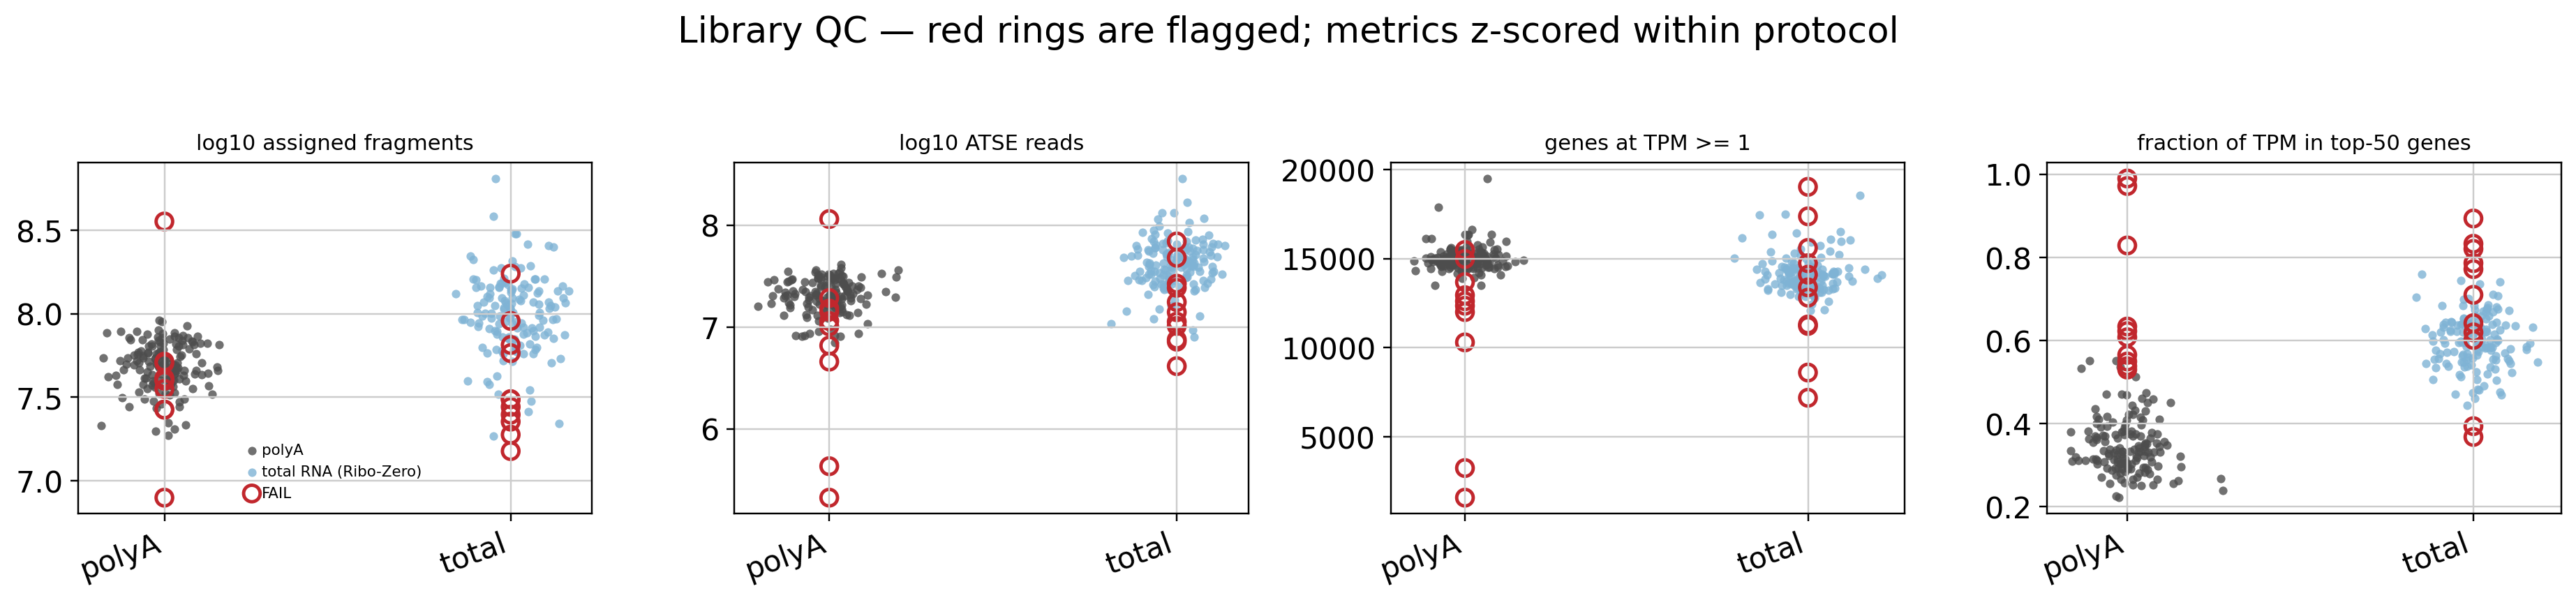


kept 295 / 316 libraries
  by protocol: {'polyA': 148, 'total RNA (Ribo-Zero)': 147}
  RNA samples: 155  |  with a complete polyA+total pair: 140
  cell types: 155  |  organ systems: 23
  SRR runs kept: 2,050 / 2,228

NOTE: if a PCA outlier from the plots below does NOT appear in the fail list above, it is
technically sound — it is a biological outlier (rare cell type), and should be KEPT.


In [11]:
# ── Library QC: drop failed libraries BEFORE analysing expression or splicing ──
# Flag on TECHNICAL metrics only. We deliberately do NOT flag on PCA position: a library sitting
# far out in PCA may simply be a rare cell type, and dropping it for being far away would be
# circular — it would delete the biology we are trying to measure.
#
# All metrics are robust-z'd WITHIN protocol: polyA and Ribo-Zero have genuinely different
# distributions (depth, exonic fraction, histone content), so a shared threshold would just
# re-flag "is total RNA".
assert list(ge_gsm.obs_names) == list(splice_gsm.obs_names), "ge_gsm / splice_gsm are misaligned"

tpm = np.asarray(ge_gsm.layers["tpm"])
mt  = [g for g in ge_gsm.var_names if str(g).startswith("MT-")]

qc = ge_gsm.obs[["cell_type", "organ_system", "protocol", "sample_id", "n_runs"]].copy()
qc["depth"]      = ge_gsm.obs["total_counts"].values                      # assigned fragments
qc["atse_reads"] = splice_gsm.obs["atse_reads"].values                    # ATSE coverage
qc["n_genes"]    = (tpm >= 1).sum(1)                                      # genes at TPM >= 1
qc["top50_frac"] = np.sort(tpm, axis=1)[:, -50:].sum(1) / 1e6            # complexity (1 = degenerate)
qc["mt_frac"]    = np.asarray(ge_gsm[:, mt].layers["tpm"]).sum(1) / 1e6 if mt else 0.0

METRICS = {                     # (column, direction that is BAD)
    "log_depth":  (np.log10(qc["depth"] + 1),      "low"),
    "log_atse":   (np.log10(qc["atse_reads"] + 1), "low"),
    "n_genes":    (qc["n_genes"].astype(float),    "low"),
    "top50_frac": (qc["top50_frac"],               "high"),   # few genes hog the library
    "mt_frac":    (qc["mt_frac"],                  "high"),   # degraded RNA
}

def robust_z(x):
    med = x.median()
    mad = (x - med).abs().median()
    return (x - med) / (1.4826 * mad + 1e-9)

Z = 4.0     # conservative: n=316 is small, over-pruning costs more than a couple of odd libraries
fail = pd.Series(False, index=qc.index)
for name, (vals, bad) in METRICS.items():
    qc[name] = vals
    z = qc.groupby("protocol", observed=True)[name].transform(robust_z)
    qc["z_" + name] = z
    fail |= (z < -Z) if bad == "low" else (z > Z)
qc["fail"] = fail

print(f"QC: {fail.sum()} / {len(qc)} libraries flagged (robust |z| > {Z}, within protocol)\n")
if fail.any():
    cols = ["cell_type", "protocol", "depth", "atse_reads", "n_genes", "top50_frac", "mt_frac"]
    display(qc.loc[fail, cols].assign(
        depth=lambda d: (d.depth / 1e6).round(1),
        atse_reads=lambda d: (d.atse_reads / 1e6).round(2),
        top50_frac=lambda d: d.top50_frac.round(3),
        mt_frac=lambda d: d.mt_frac.round(3)))
    for lib in qc.index[fail]:
        why = [f"{n} z={qc.loc[lib, 'z_' + n]:+.1f}" for n, (_, b) in METRICS.items()
               if (qc.loc[lib, "z_" + n] < -Z if b == "low" else qc.loc[lib, "z_" + n] > Z)]
        print(f"  {lib}  {qc.loc[lib, 'cell_type']}  ({qc.loc[lib, 'protocol']}):  {', '.join(why)}")

# ── Plot the QC space, pass vs fail ───────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
panels = [("log_depth", "log10 assigned fragments"), ("log_atse", "log10 ATSE reads"),
          ("n_genes", "genes at TPM >= 1"), ("top50_frac", "fraction of TPM in top-50 genes")]
for ax, (col, lab) in zip(axes, panels):
    for p, c in PROTO_COL.items():
        m = (qc["protocol"] == p) & ~qc["fail"]
        ax.scatter(np.random.normal(list(PROTO_COL).index(p), .07, m.sum()), qc.loc[m, col],
                   s=16, c=c, alpha=.8, linewidths=0, label=p if col == "log_depth" else None)
    m = qc["fail"]
    if m.any():
        ax.scatter([list(PROTO_COL).index(p) for p in qc.loc[m, "protocol"]], qc.loc[m, col],
                   s=60, facecolors="none", edgecolors="#C1272D", linewidths=1.6,
                   label="FAIL" if col == "log_depth" else None)
    ax.set_xticks(range(len(PROTO_COL)))
    ax.set_xticklabels([p.split()[0] for p in PROTO_COL], rotation=20, ha="right")
    ax.set_title(lab, fontsize=10)
axes[0].legend(fontsize=7, frameon=False)
fig.suptitle("Library QC — red rings are flagged; metrics z-scored within protocol", y=1.03)
plt.tight_layout(); plt.show()

# ── Apply the filter to BOTH objects, keeping them aligned ────────────────────
keep = (~qc["fail"]).values
ge_gsm     = ge_gsm[keep].copy()
splice_gsm = splice_gsm[keep].copy()

# a sample loses its protocol pair if one of its two libraries was dropped
n_lib = ge_gsm.obs.groupby("sample_id", observed=True).size()
ge_gsm.obs["has_pair"]     = ge_gsm.obs["sample_id"].map(n_lib).eq(2).values
splice_gsm.obs["has_pair"] = ge_gsm.obs["has_pair"].values

print(f"\nkept {ge_gsm.n_obs} / {len(qc)} libraries")
print("  by protocol:", ge_gsm.obs["protocol"].value_counts().to_dict())
print(f"  RNA samples: {ge_gsm.obs['sample_id'].nunique()}  |  "
      f"with a complete polyA+total pair: {ge_gsm.obs['has_pair'].sum() // 2}")
print(f"  cell types: {ge_gsm.obs['cell_type'].astype(str).nunique()}  |  "
      f"organ systems: {ge_gsm.obs['organ_system'].astype(str).nunique()}")
# run-level object restricted to the surviving libraries (for the run-vs-library PCA panel)
ge_run = ge[ge.obs["gsm"].astype(str).isin(set(ge_gsm.obs_names))].copy()
print(f"  SRR runs kept: {ge_run.n_obs:,} / {ge.n_obs:,}")

print("\nNOTE: if a PCA outlier from the plots below does NOT appear in the fail list above, it is")
print("technically sound — it is a biological outlier (rare cell type), and should be KEPT.")


extracting highly variable genes
    finished (0:00:00)
computing PCA
    with n_comps=20
    finished (0:00:01)
extracting highly variable genes
    finished (0:00:00)
computing PCA
    with n_comps=20
    finished (0:00:00)
libraries 43  |  runs 297  |  cell types 24
libraries by protocol: {'total RNA (Ribo-Zero)': 23, 'polyA': 20}

Variance in the top-10 PCs (run-level PCA), by nesting level:
   organ         28.7%
   cell type     70.2%
   protocol       1.1%
   run (SRR)      0.1%

Euclidean distance between GSM libraries in top-10 PC space:
   same cell type (polyA vs total of one RNA) median    8.9   (n=19 pairs)
   diff cell type, same organ                 median   15.3   (n=578 pairs)
   different organ                            median   76.7   (n=306 pairs)


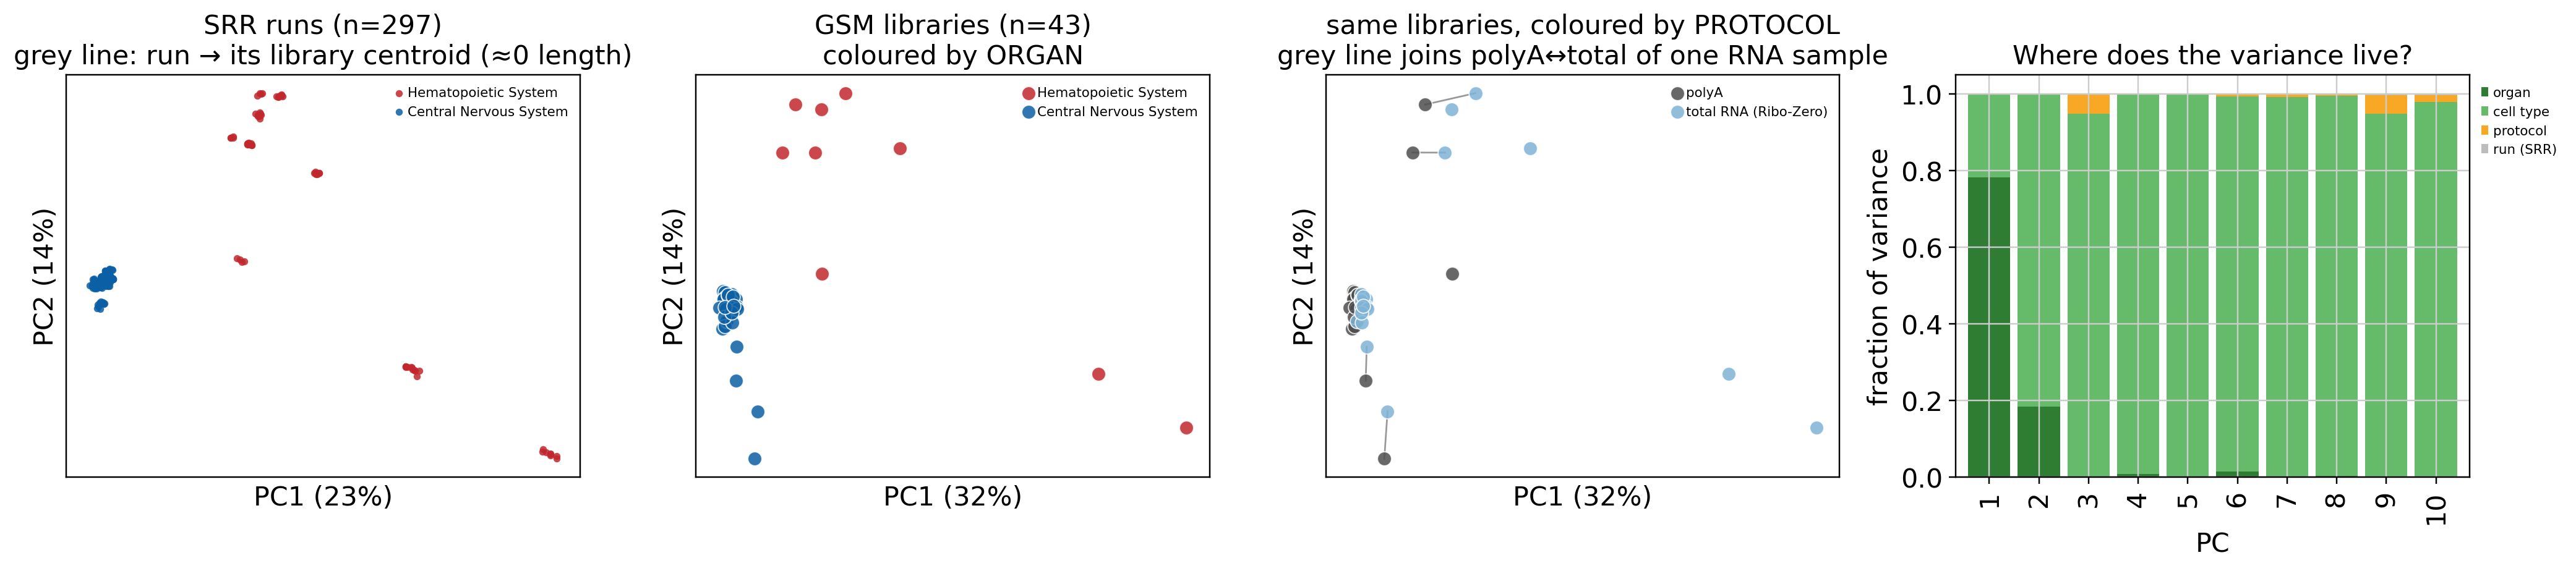


Panel 3 is the decision plot: if the grey lines are SHORT (polyA and total RNA of the same
sample land together) protocol is a minor axis and we can train on all 316. If they are LONG,
or if they all point the same way, protocol is structure the model will learn — pick one.


In [12]:
# ── PCA on TWO organ systems only ─────────────────────────────────────────────
# Nesting, now that we know what the GSMs are:
#     organ  >  cell type (= one RNA sample)  >  protocol (polyA | total RNA)  >  SRR run
# Hematopoietic alone holds monocytes / T / B / NK / granulocytes / CD34+, so "within organ" is
# NOT "between replicates" — that was the flaw in the first version of this plot. And because
# there is exactly one RNA sample per cell type, the replicate level IS the protocol level.
from scipy.spatial.distance import pdist, squareform

PAIR = ["Hematopoietic System", "Central Nervous System"]
COLORS = {PAIR[0]: "#C1272D", PAIR[1]: "#0B5FA5"}

def pca_subset(adata, organs, n_top_genes=2000, n_comps=20):
    sub = adata[adata.obs["organ_system"].astype(str).isin(organs)].copy()
    sub.obs["organ_system"] = pd.Categorical(sub.obs["organ_system"].astype(str), categories=organs)
    sc.pp.highly_variable_genes(sub, n_top_genes=n_top_genes)   # X is log-scale ✓
    sub = sub[:, sub.var["highly_variable"]].copy()
    sc.pp.scale(sub, max_value=10)
    sc.tl.pca(sub, n_comps=min(n_comps, sub.n_obs - 1), svd_solver="arpack")
    return sub

lib = pca_subset(ge_gsm, PAIR)   # 1 dot = 1 GSM library
run = pca_subset(ge_run, PAIR)   # 1 dot = 1 SRR run (QC-passing libraries only)
run.obs["gsm"]      = ge_run.obs.loc[run.obs_names, "gsm"].astype(str).values
run.obs["protocol"] = geo.loc[run.obs["gsm"], "protocol"].values

print(f"libraries {lib.n_obs}  |  runs {run.n_obs}  |  "
      f"cell types {lib.obs.cell_type.astype(str).nunique()}")
print("libraries by protocol:", lib.obs["protocol"].value_counts().to_dict())

# ── 4-level nested variance decomposition ────────────────────────────────────
def variance_components(emb, organ, ctype, gsm, n_pc=10):
    rows = []
    for k in range(n_pc):
        y     = pd.Series(emb[:, k])
        grand = y.mean()
        m_org = y.groupby(organ).transform("mean")   # organ mean
        m_ct  = y.groupby(ctype).transform("mean")   # cell-type mean (nested in organ)
        m_gsm = y.groupby(gsm).transform("mean")     # library mean  (nested in cell type)
        rows.append({
            "PC": k + 1,
            "organ":     ((m_org - grand) ** 2).sum(),   # between organs
            "cell type": ((m_ct  - m_org) ** 2).sum(),   # cell types within organ
            "protocol":  ((m_gsm - m_ct)  ** 2).sum(),   # polyA vs total, SAME RNA sample
            "run (SRR)": ((y     - m_gsm) ** 2).sum(),   # runs of the same library
        })
    vc = pd.DataFrame(rows).set_index("PC")
    return vc.div(vc.sum(1), axis=0), vc.sum() / vc.sum().sum()

LEVELS  = ["organ", "cell type", "protocol", "run (SRR)"]
PALETTE = {"organ": "#2E7D32", "cell type": "#66BB6A",
           "protocol": "#F9A825", "run (SRR)": "#BDBDBD"}

per_pc, overall = variance_components(
    run.obsm["X_pca"],
    run.obs["organ_system"].astype(str).values,
    run.obs["cell_type"].astype(str).values,
    run.obs["gsm"].values)

print("\nVariance in the top-10 PCs (run-level PCA), by nesting level:")
for lvl in LEVELS:
    print(f"   {lvl:12s} {100*overall[lvl]:5.1f}%")

# ── Distances between libraries: the direct 'organ vs replicate' answer ──────
Z  = lib.obsm["X_pca"][:, :10]
ct = lib.obs["cell_type"].astype(str).values
og = lib.obs["organ_system"].astype(str).values
pr = lib.obs["protocol"].astype(str).values
i, j = np.triu_indices(len(Z), 1)
d = squareform(pdist(Z))[i, j]
grp = np.where(ct[i] == ct[j], "same cell type (polyA vs total of one RNA)",
      np.where(og[i] == og[j], "diff cell type, same organ", "different organ"))
dist = pd.DataFrame({"d": d, "grp": grp})

print("\nEuclidean distance between GSM libraries in top-10 PC space:")
for g in ["same cell type (polyA vs total of one RNA)", "diff cell type, same organ", "different organ"]:
    s = dist.loc[dist.grp == g, "d"]
    print(f"   {g:42s} median {s.median():6.1f}   (n={len(s):,} pairs)")

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))

E   = run.obsm["X_pca"]
cen = (pd.DataFrame(E[:, :2], index=run.obs_names)
         .groupby(run.obs["gsm"].values).transform("mean").values)
for n in range(run.n_obs):
    axes[0].plot([E[n, 0], cen[n, 0]], [E[n, 1], cen[n, 1]], color="0.75", lw=.5, zorder=1)
for o in PAIR:
    m = (run.obs["organ_system"].astype(str) == o).values
    axes[0].scatter(E[m, 0], E[m, 1], s=14, c=COLORS[o], label=o, alpha=.85, zorder=2, linewidths=0)
vr = run.uns["pca"]["variance_ratio"]
axes[0].set_title(f"SRR runs (n={run.n_obs})\ngrey line: run → its library centroid (≈0 length)")
axes[0].set_xlabel(f"PC1 ({100*vr[0]:.0f}%)"); axes[0].set_ylabel(f"PC2 ({100*vr[1]:.0f}%)")

L  = lib.obsm["X_pca"]
vl = lib.uns["pca"]["variance_ratio"]
for o in PAIR:                                              # panel 2: by ORGAN
    m = (lib.obs["organ_system"].astype(str) == o).values
    axes[1].scatter(L[m, 0], L[m, 1], s=55, c=COLORS[o], label=o, alpha=.85,
                    edgecolors="w", linewidths=.6)
axes[1].set_title(f"GSM libraries (n={lib.n_obs})\ncoloured by ORGAN")

for p in PROTO_COL:                                         # panel 3: by PROTOCOL
    m = pr == p
    axes[2].scatter(L[m, 0], L[m, 1], s=55, c=PROTO_COL[p], label=p, alpha=.85,
                    edgecolors="w", linewidths=.6, zorder=2)
for c in pd.unique(ct):                                     # join the polyA/total pair of one RNA
    m = ct == c
    axes[2].plot(L[m, 0], L[m, 1], "-", color="0.6", lw=.9, zorder=1)
axes[2].set_title("same libraries, coloured by PROTOCOL\ngrey line joins polyA↔total of one RNA sample")

for ax in axes[1:3]:
    ax.set_xlabel(f"PC1 ({100*vl[0]:.0f}%)"); ax.set_ylabel(f"PC2 ({100*vl[1]:.0f}%)")
for ax in axes[:3]:
    ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=7, frameon=False)

per_pc[LEVELS].plot.bar(stacked=True, ax=axes[3], width=.85, color=PALETTE)
axes[3].set_ylabel("fraction of variance"); axes[3].set_xlabel("PC")
axes[3].set_title("Where does the variance live?")
axes[3].legend(fontsize=7, frameon=False, bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()

print("\nPanel 3 is the decision plot: if the grey lines are SHORT (polyA and total RNA of the same")
print("sample land together) protocol is a minor axis and we can train on all 316. If they are LONG,")
print("or if they all point the same way, protocol is structure the model will learn — pick one.")

libraries: Hematopoietic System n=9   |   Central Nervous System n=34
(each is one polyA or one total-RNA library; the two of a cell type share an RNA sample)

PTPRC   median TPM  Hematopoietic:     168.5   Central Nervous:       0.0
CD14    median TPM  Hematopoietic:     147.5   Central Nervous:       0.4
CD3D    median TPM  Hematopoietic:       0.5   Central Nervous:       0.0
GFAP    median TPM  Hematopoietic:       0.1   Central Nervous:       1.4
AQP4    median TPM  Hematopoietic:       0.0   Central Nervous:       0.1
SLC1A3  median TPM  Hematopoietic:       1.1   Central Nervous:       7.0


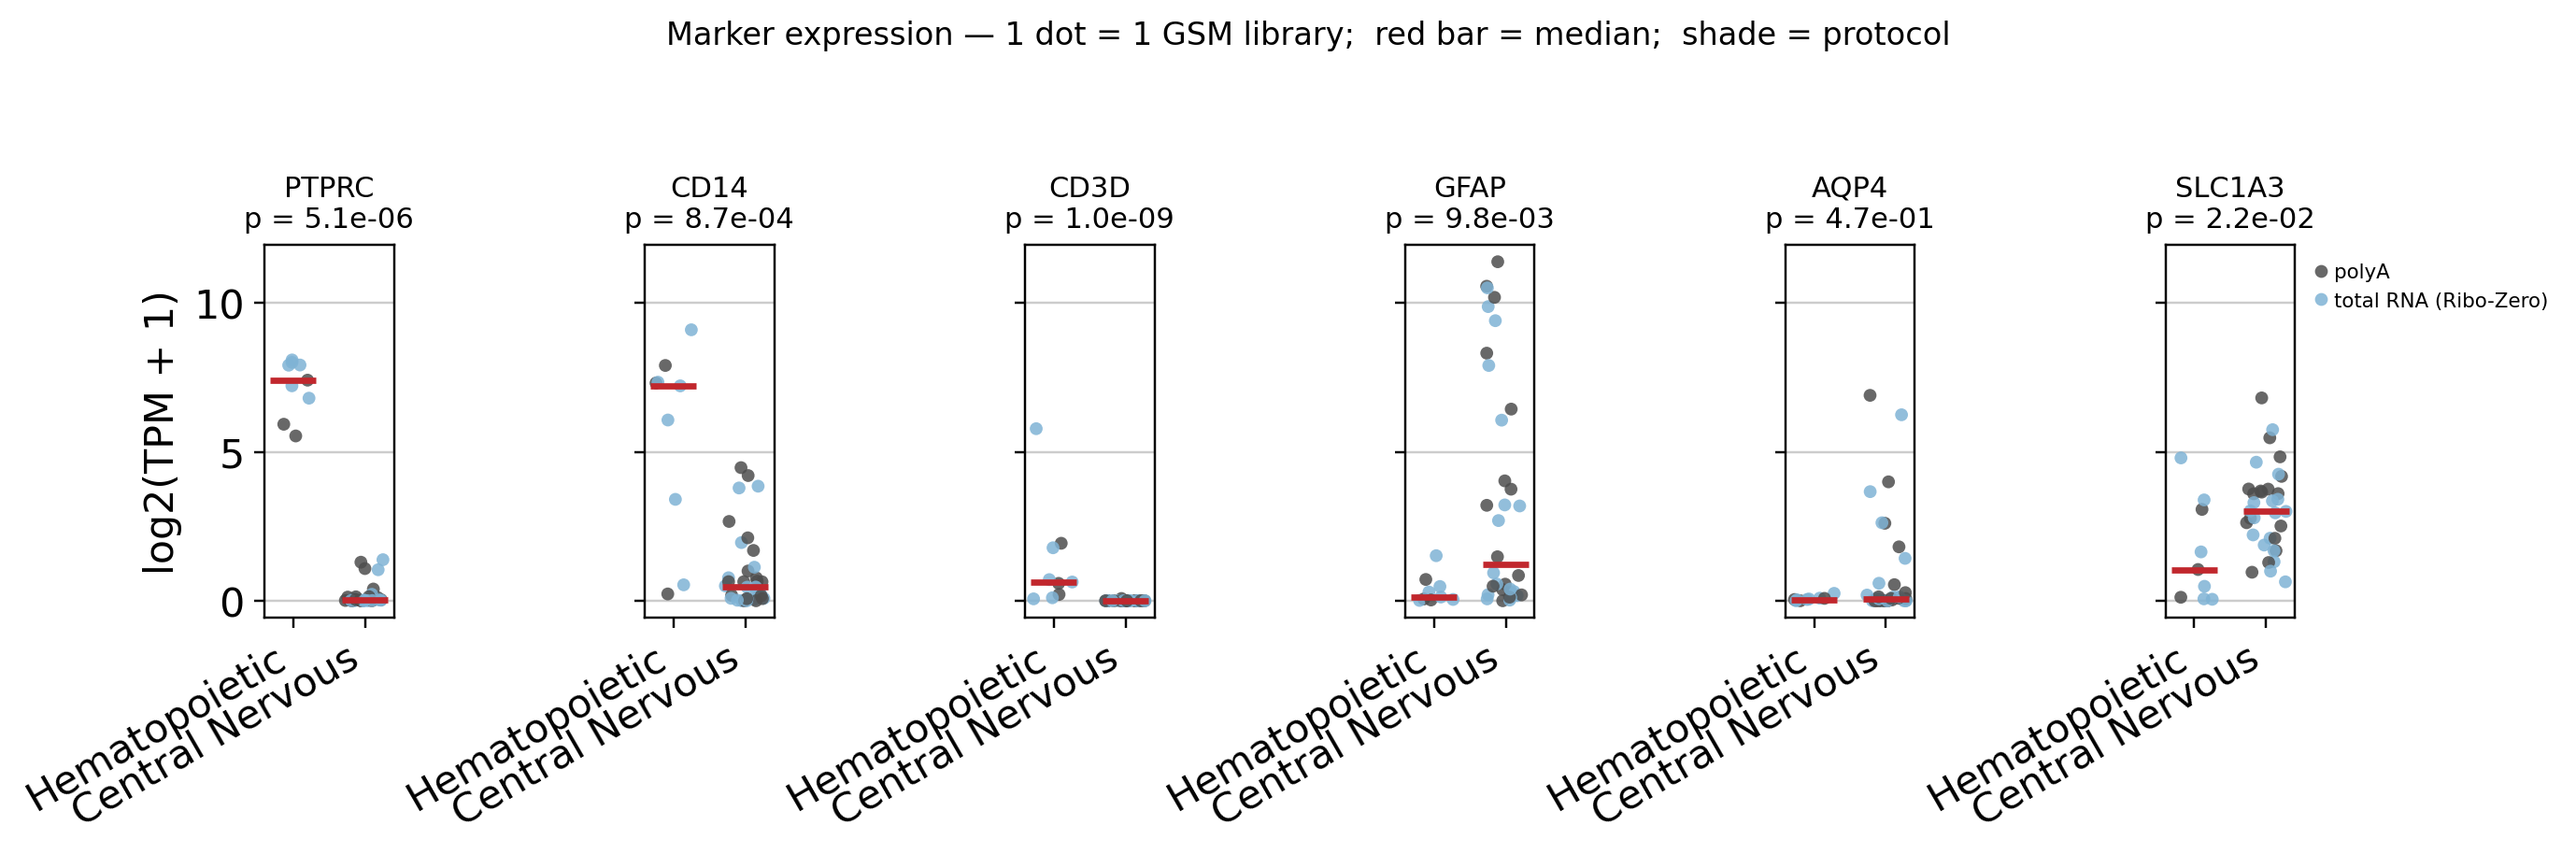

In [13]:
# ── Marker jitter plots: 1 dot = 1 GSM library, y = log2(TPM + 1) ─────────────
# Units: featureCounts fragments -> TPM (÷ gene length, rescale to 1e6) -> log2(TPM + 1).
# Dot shade = library protocol, so you can see whether polyA and total RNA of the same RNA
# sample give the same marker call (they should — markers are polyadenylated mRNAs).
from scipy.stats import mannwhitneyu

PANEL = ["PTPRC", "CD14", "CD3D",      # blood
         "GFAP", "AQP4", "SLC1A3"]     # brain
PANEL = [g for g in PANEL if g in ge_gsm.var_names]

sub = ge_gsm[ge_gsm.obs["organ_system"].astype(str).isin(PAIR)].copy()
df  = pd.DataFrame(np.asarray(sub[:, PANEL].layers["tpm"]), columns=PANEL, index=sub.obs_names)
df["organ_system"] = sub.obs["organ_system"].astype(str).values
df["protocol"]     = sub.obs["protocol"].astype(str).values

n = df["organ_system"].value_counts()
print(f"libraries: {PAIR[0]} n={n[PAIR[0]]}   |   {PAIR[1]} n={n[PAIR[1]]}")
print("(each is one polyA or one total-RNA library; the two of a cell type share an RNA sample)\n")

fig, axes = plt.subplots(1, len(PANEL), figsize=(2.1 * len(PANEL), 4.0), sharey=True)
short = [o.replace(" System", "") for o in PAIR]

for ax, g in zip(axes, PANEL):
    d = df[[g, "organ_system", "protocol"]].rename(columns={g: "tpm"})
    d["log2tpm1"] = np.log2(d["tpm"] + 1)

    sns.stripplot(data=d, x="organ_system", y="log2tpm1", order=PAIR, hue="protocol",
                  palette=PROTO_COL, ax=ax, size=4.5, alpha=.85, jitter=.28, linewidth=0,
                  legend=(g == PANEL[-1]))
    for i, o in enumerate(PAIR):                                   # median bar
        ax.hlines(d.loc[d.organ_system == o, "log2tpm1"].median(), i - .32, i + .32,
                  color="#C1272D", lw=2.2, zorder=5)

    a = d.loc[d.organ_system == PAIR[0], "tpm"]
    b = d.loc[d.organ_system == PAIR[1], "tpm"]
    p = mannwhitneyu(a, b).pvalue
    ax.set_title(f"{g}\np = {p:.1e}", fontsize=10)
    ax.set_xlabel(""); ax.set_xticks(range(len(PAIR)))
    ax.set_xticklabels(short, rotation=30, ha="right")
    print(f"{g:7s} median TPM  {short[0]}: {a.median():9.1f}   {short[1]}: {b.median():9.1f}")

axes[0].set_ylabel("log2(TPM + 1)")
if axes[-1].get_legend():
    axes[-1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Marker expression — 1 dot = 1 GSM library;  red bar = median;  shade = protocol",
             y=1.04, fontsize=11)
plt.tight_layout(); plt.show()

## 5. PCA on gene expression

HVG → scale → PCA. We keep a copy of the full log-TPM in `raw` so marker plots stay usable.

## 6. LeafletFA — **no batching** (all libraries in one optimization)

This is the point of using this dataset: it's small enough to fit the whole thing in one
optimization, so we can check that minibatching isn't distorting the learned programs.
`pipelines/05_leafletfa/run_training.py` always runs a *multi-pass minibatch* loop; here we call
`LeafletFA` directly on the full AnnData — one batch, one optimization.

**We train on `splice_gsm` (316 GSM libraries), not `splice` (2,228 SRR runs).** See §4b: SRRs are
sequencing runs of the same library, they carry ~0% of the variance, and their uneven counts
(4 / 8 / 16) would silently give some libraries 4× the ELBO weight of others.

**Set `PROTOCOL` below after looking at the §4b protocol panel:**

| `PROTOCOL` | n | when to use |
|---|---|---|
| `None` | 316 | polyA and total RNA of a sample co-locate ⇒ protocol is a minor axis. Keeps the paired design as a built-in PSI reproducibility test. |
| `"polyA"` | ~158 | protocol is a major axis. Cleanest for splicing — no nascent pre-mRNA inflating PSI. One library per cell type. |
| `"total RNA (Ribo-Zero)"` | ~158 | deeper, captures non-polyadenylated transcripts, but nascent RNA systematically shifts PSI. |

**Note on parity with `run_0`:** the SLURM run used `waypoints_use=True` and `max_junctions=10`, on
the SRR-level object. We match the junction filter below but use random init
(`waypoints_use=False`) — so expect programs to be *similar but not identical* to run_0. The
row-set differs too (libraries, not runs), so this is not a strict batch-equivalence comparison
unless you rerun the SLURM side on `splice_gsm` as well.

**Fast draft:** `N_ATSES` in the next cell subsamples ATSEs (default 10,000) so the run finishes
quickly while you iterate on K / diagnostics. Sampling is at the **event** level, not the junction
level — an ATSE's total read count is stored on every one of its junction columns, so keeping only
part of an event would break PSI. **Set `N_ATSES = None` for the final model**; a 10k-ATSE model is
fine for "do the programs track cell identity?" but its `psi` covers only ~8% of the junctions and
should not be used for the conservation analysis or the batch-equivalence comparison.


In [ ]:
from leafletfa import LeafletFA

# ── Choose the training set ───────────────────────────────────────────────────
PROTOCOL      = None     # None = all 316 libraries | "polyA" | "total RNA (Ribo-Zero)"
MAX_JUNCTIONS = None     # None = keep ALL junctions (no ATSE-size filter). Set to e.g. 10 to match run_0.
N_ATSES       = 10_000   # ⚠ DRAFT: subsample this many ATSEs for a fast run. None = all ATSEs (final model).
SEED          = 0

base = splice_gsm if PROTOCOL is None else \
       splice_gsm[splice_gsm.obs["protocol"] == PROTOCOL].copy()

# NB: `base.var["num_junctions"] <= None` is all-False in pandas, so a None threshold used to
# silently select ZERO junctions and hand LeafletFA a (316, 0) matrix. Branch explicitly.
if MAX_JUNCTIONS is None:
    sp_train = base.copy()
else:
    sp_train = base[:, base.var["num_junctions"] <= MAX_JUNCTIONS].copy()

# ── Subsample whole ATSEs (never individual junctions) ────────────────────────
# cell_by_cluster_matrix stores an ATSE's TOTAL read count on every junction column belonging to
# that ATSE. Sampling junctions would leave denominators that still count reads from junctions no
# longer in the matrix, so PSI for the survivors would be silently deflated and the ATSE's
# junctions would no longer sum to 1. Sampling event_ids keeps junction/cluster counts consistent.
# event_id is categorical; work in str space so value_counts/isin don't drag category dtypes around.
ev_all = sp_train.var["event_id"].astype(str)
n_orig = ev_all.value_counts()          # junctions per ATSE, BEFORE subsampling

if N_ATSES is not None:
    events = n_orig.index.to_numpy()
    if len(events) > N_ATSES:
        keep = set(np.random.default_rng(SEED).choice(events, size=N_ATSES, replace=False))
        sp_train = sp_train[:, ev_all.isin(keep).to_numpy()].copy()
        print(f"⚠ DRAFT RUN — ATSE subsample: {len(events):,} -> "
              f"{sp_train.var['event_id'].astype(str).nunique():,} ATSEs (seed {SEED}). "
              f"Set N_ATSES = None for the final model.")
    else:
        print(f"N_ATSES={N_ATSES:,} >= {len(events):,} available — keeping all ATSEs.")

assert sp_train.shape[1] > 0, "junction filter removed everything — check MAX_JUNCTIONS / N_ATSES"
sp_train.var["junction_id_index"] = np.arange(sp_train.shape[1])

# Sanity: every retained ATSE kept ALL of its junctions (a split cluster would break PSI).
# Compare via dict lookup, not Series ==: the two indexes are CategoricalIndexes and pandas
# raises "Can only compare identically-labeled Series objects" rather than aligning them.
n_kept = sp_train.var["event_id"].astype(str).value_counts()
split  = [e for e, k in n_kept.items() if k != n_orig[e]]
assert not split, f"{len(split)} ATSEs were split — cluster counts would be inconsistent"

print(f"training on: {'ALL protocols' if PROTOCOL is None else PROTOCOL}")
print(f"splice_gsm {splice_gsm.shape} -> {sp_train.shape} (num_junctions <= {MAX_JUNCTIONS})")
print("libraries by protocol:", sp_train.obs["protocol"].value_counts().to_dict())
print(f"cell types: {sp_train.obs['cell_type'].astype(str).nunique()}  |  "
      f"organ systems: {sp_train.obs['organ_system'].astype(str).nunique()}  |  "
      f"RNA samples: {sp_train.obs['sample_id'].nunique()}")

assert "cell_by_junction_matrix" in sp_train.layers
assert "cell_by_cluster_matrix" in sp_train.layers
assert sp_train.n_obs == len(set(sp_train.obs_names)), "duplicate library ids"
print(f"ATSEs: {sp_train.var['event_id'].nunique():,}")

In [ ]:
# ── (optional) Waypoint initialization ────────────────────────────────────────
# LeafletFA does NOT compute waypoints for you: with waypoints_use=True it only *looks* for
#     adata.varm[f"psi_init_{K}_waypoints"]   (J x K)
#     adata.obsm[f"phi_init_{K}_waypoints"]   (N x K)
# and raises "PSI and PHI initializations for K waypoints not found" if they are absent. The SLURM
# pipeline builds them itself (run_training.py, "Pre-computing waypoints on full dataset"); this
# cell is that block, ported to the notebook.
#
# This MUST run after the ATSE subsample: psi_init has one row per junction, so waypoints computed
# on a different junction set would be the wrong shape (or, worse, the right shape but misaligned).
#
# Unsupervised on purpose — max-min sampling over PCs of junction usage, never stratified by cell
# type. The paper claims LeafletFA recovers programs without cell-type labels, so labels must not
# enter through the initialization of the model whose programs then recover them.
import leafletfa.waypoints as wayp
from sklearn.decomposition import TruncatedSVD

WAYPOINTS = True     # True = waypoint init (matches run_0) | False = random init
RHO_BB    = 0.1      # overdispersion for the beta-binomial weights used when centering

if WAYPOINTS:
    N_WP  = K_WP = 20                                    # must equal the K used in the next cell
    N_PCA = min(20, sp_train.n_obs - 1, sp_train.n_vars - 1)
    N_DIM = min(20, N_PCA)
    METACELL_SIZE = min(200, sp_train.n_obs // N_WP)      # 295 libs / 30 waypoints -> 9 per metacell

    # ── Centered PSI, for the PCA that selects waypoints ──────────────────────
    # run_training.py runs its waypoint PCA on `junc_ratio_centered` when that layer exists. We
    # don't have it, so build it here. Do NOT call wayp.calculate_centered_psi: it pairs
    # junction_counts.data with cluster_counts.data POSITIONALLY, which assumes the two layers
    # share a sparsity pattern. Ours don't — an ATSE can have reads while one of its junctions has
    # zero, so cluster has strictly more nonzeros — and that function would silently divide each
    # junction by some other junction's ATSE total. 295 x J is tiny, so just do it densely.
    Jc = np.asarray(sp_train.layers["cell_by_junction_matrix"].todense(), dtype=np.float64)
    Cc = np.asarray(sp_train.layers["cell_by_cluster_matrix"].todense(),  dtype=np.float64)
    obs_mask = Cc > 0                                     # PSI is only defined where the ATSE has reads
    psi_raw  = np.divide(Jc, Cc, out=np.zeros_like(Jc), where=obs_mask)

    # Beta-binomial precision weights: a PSI from 500 reads is worth more than one from 3.
    w = np.where(obs_mask, Cc / (1.0 + (Cc - 1.0) * RHO_BB), 0.0)
    junc_means = (w * psi_raw).sum(0) / np.maximum(w.sum(0), 1e-12)   # weighted mean PSI per junction
    Y = np.where(obs_mask, psi_raw - junc_means, 0.0)     # unobserved -> 0 = "no deviation from mean"
    print(f"centered PSI: {Y.shape}, {100 * obs_mask.mean():.1f}% of entries observed, "
          f"mean |Y| = {np.abs(Y[obs_mask]).mean():.3f}")

    print(f"PCA on centered PSI ({sp_train.n_obs} libraries x {sp_train.n_vars:,} junctions, "
          f"{N_PCA} comps)...")
    svd   = TruncatedSVD(n_components=N_PCA, random_state=42)
    X_pca = svd.fit_transform(Y) * svd.singular_values_
    var_wp = svd.explained_variance_ratio_
    print(f"  PC1 {100*var_wp[0]:.1f}%  PC2 {100*var_wp[1]:.1f}%  "
          f"top{N_PCA} cumulative {100*var_wp.sum():.1f}%")

    print(f"Finding {N_WP} waypoints (unsupervised max-min, metacell size {METACELL_SIZE})...")
    wp_idx    = wayp.max_min_sampling(X_pca, N_WP, num_components=N_DIM, seed=42)
    metacells = wayp.assign_nearest_cells(wp_idx, X_pca, num_nearest=METACELL_SIZE)

    # psi/phi init come from RAW PSI, not the centered matrix: psi is a probability the model plugs
    # straight into a Beta-Binomial, so it must live in [0, 1]. Centered values are signed.
    # (run_training.py makes the same split — centered for the PCA, junc_ratio for the init.)
    psi_inits, phi_inits = wayp.generate_initializations(
        sp_train.X, {N_WP: wp_idx}, {N_WP: metacells}, epsilon=0.001)
    psi_wp, phi_wp = np.asarray(psi_inits[0]), np.asarray(phi_inits[0])

    # LeafletFA reads varm as (J, K) and transposes it internally; obsm is (N, K).
    assert psi_wp.shape == (sp_train.n_vars, N_WP), f"psi_init {psi_wp.shape} != (J, K)"
    assert phi_wp.shape == (sp_train.n_obs,  N_WP), f"phi_init {phi_wp.shape} != (N, K)"

    sp_train.varm[f"psi_init_{K_WP}_waypoints"] = psi_wp
    sp_train.obsm[f"phi_init_{K_WP}_waypoints"] = phi_wp
    sp_train.obsm["X_pca_centered"] = X_pca                # for the plot below
    print(f"attached psi_init_{K_WP}_waypoints {psi_wp.shape} and "
          f"phi_init_{K_WP}_waypoints {phi_wp.shape}")
    del Jc, Cc, w, psi_raw
else:
    print("random init (no waypoints attached)")

In [ ]:
# ── PCA of the CENTERED PSI, with the waypoints marked ────────────────────────
# This is the space max_min_sampling actually walked, so it shows what the init is seeded from.
# What to look for: waypoints should sit at the EXTREMES / spread across the cloud (that is the
# point of max-min — cover the space), not cluster in the dense centre. A waypoint set that all
# lands in one blob means the init only sees one part of the data.
assert WAYPOINTS, "run the waypoint cell with WAYPOINTS = True first"

Xp    = sp_train.obsm["X_pca_centered"]
organ = sp_train.obs["organ_system"].astype(str).values
proto = sp_train.obs["protocol"].astype(str).values
ctype = sp_train.obs["cell_type"].astype(str).values
is_wp = np.zeros(sp_train.n_obs, bool); is_wp[wp_idx] = True

def _mark_waypoints(ax, xi, yi):
    ax.scatter(Xp[wp_idx[1:], xi], Xp[wp_idx[1:], yi], s=70, facecolors="none",
               edgecolors="black", linewidths=1.4, label=f"{len(wp_idx)} waypoints", zorder=5)
    ax.scatter(Xp[wp_idx[0], xi], Xp[wp_idx[0], yi], s=150, marker="*", c="#C1272D",
               edgecolors="black", linewidths=.8, label="first waypoint (random seed)", zorder=6)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))

# (a) PC1/PC2 by organ system
organs = sorted(set(organ))
cmap = plt.colormaps.get_cmap("tab20")
for i, o in enumerate(organs):
    m = organ == o
    axes[0].scatter(Xp[m, 0], Xp[m, 1], s=26, color=cmap(i % 20), alpha=.85,
                    linewidths=0, label=o)
_mark_waypoints(axes[0], 0, 1)
axes[0].set_title(f"Centered PSI PCA — organ system\nPC1 {100*var_wp[0]:.1f}%  PC2 {100*var_wp[1]:.1f}%")
axes[0].legend(fontsize=5.5, ncol=2, loc="best", frameon=False)

# (b) PC1/PC2 by protocol — is the top PC just polyA vs Ribo-Zero?
for p, c in PROTO_COL.items():
    m = proto == p
    axes[1].scatter(Xp[m, 0], Xp[m, 1], s=26, c=c, alpha=.85, linewidths=0, label=p)
_mark_waypoints(axes[1], 0, 1)
axes[1].set_title("Centered PSI PCA — protocol\n(if PC1 splits these, PC1 is technical)")
axes[1].legend(fontsize=7, frameon=False)

# (c) PC2/PC3, waypoints vs the rest — max-min uses all 20 PCs, not just the first two,
#     so a waypoint that looks "interior" in PC1/PC2 may be an extreme in a higher PC.
axes[2].scatter(Xp[~is_wp, 1], Xp[~is_wp, 2], s=26, c="0.75", alpha=.8, linewidths=0, label="library")
_mark_waypoints(axes[2], 1, 2)
axes[2].set_title(f"PC2 vs PC3\n(max-min ran on {N_DIM} PCs, not 2)")
axes[2].set_xlabel("PC2"); axes[2].set_ylabel("PC3")
axes[2].legend(fontsize=7, frameon=False)

for ax in axes[:2]:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.suptitle(f"Waypoint initialization: {len(wp_idx)} waypoints over {sp_train.n_obs} libraries", y=1.02)
plt.tight_layout(); plt.show()

# Which libraries got picked, and do they cover the biology?
print(f"waypoints span {pd.Series(ctype[wp_idx]).nunique()} cell types / "
      f"{pd.Series(organ[wp_idx]).nunique()} of {len(organs)} organ systems  "
      f"(protocol: {pd.Series(proto[wp_idx]).value_counts().to_dict()})")
display(pd.DataFrame({"library": sp_train.obs_names[wp_idx], "cell_type": ctype[wp_idx],
                      "organ_system": organ[wp_idx], "protocol": proto[wp_idx],
                      "PC1": Xp[wp_idx, 0].round(2), "PC2": Xp[wp_idx, 1].round(2)}))

In [ ]:
K = 20
assert not WAYPOINTS or K == K_WP, "K changed since waypoints were built — rerun the waypoint cell"
tag = "all" if PROTOCOL is None else PROTOCOL.split()[0].lower()
draft = "" if N_ATSES is None else f"_draft{N_ATSES // 1000}k"   # keep draft runs off the full-run path
OUT = f"{WD}/LEAFLETFA_MODELS/notebook_nobatch_gsm_{tag}_K{K}{draft}"   # don't clobber earlier runs
os.makedirs(OUT, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"output -> {OUT}")

model = LeafletFA(
    adata=sp_train,                 # ALL libraries — no minibatching
    K=K,
    junc_specific_prior=True,
    waypoints_use=True,            # random init (run_0 used waypoints)
    input_conc_prior=None,          # None = Beta-Binomial (model learns concentration)
    # ── SCHEDULE ────────────────────────────────────────────────────────────────
    # Matches the schedule calibrated on the Figure 2 simulation. The old settings here
    # (lr=0.001, gamma=0.01, patience=20, min_delta=200) are the ones that recover NOTHING
    # on that simulation:
    #     lr=.001 g=.01  -> psi_r=-0.01  phi_r=+0.01  agree=21%  (chance=20%)
    #     lr=.01  g=.5   -> psi_r=+0.68  phi_r=+0.73  agree=75%  <-- recovers
    # Why: phi and psi both START at the symmetric point (AutoDiagonalNormal inits every
    # sample's phi to the same prior median, and all K programs to nearly the same psi).
    # At lr<=1e-3 that symmetry never breaks, no matter how many epochs you run.
    # gamma is the TOTAL LR decay over the run (lrd = gamma**(1/num_epochs)): gamma=0.01
    # decays the LR 100x and kills it before the programs separate; gamma=0.5 decays 2x.
    num_epochs=1500,
    print_epochs=100,
    # min_delta is ABSOLUTE against an ELBO of ~1e6-1e9, i.e. a relative tolerance of ~1e-7 --
    # numerically inert. The rule degenerated to "stop after `patience` epochs with no new
    # global best", which SVI noise trips almost immediately. Disable it and watch the loss
    # curve; min_delta_rel below is the scale-free version if you want it back on.
    patience=10**6,
    min_delta=200,
    min_delta_rel=1e-5,
    ELBO_num_particles=5,
    num_samples=300,
    # Swept against GROUND TRUTH on the Figure-2 simulation (METHODS.md 11.4b):
    #   lr=0.05, gamma=0.5 -> psi_r 0.99, 100% dominant-program agreement  <- USE THIS
    #   lr=0.01, gamma=0.5 -> psi_r 0.85,  53%
    #   lr=0.001           -> CHANCE
    lr=0.05,
    gamma=0.5,
    log_wandb=False,
    loss_plot=True,
    output_dir=OUT,
    enable_cpu_optimization=(device == "cpu"),
)

model.from_anndata()
# (no initialize_triton_mask(): the dense C x J mask is gone — LeafletFA now gathers rho only at
#  the observed positions on both CPU and GPU.)

%time model.train(num_initializations=1)
model.get_all_variables()
print("done. best ELBO:", getattr(model, "best_elbo", None))

# HEALTH GATE. The obvious diagnostics LIE: on a model that recovered NOTHING, "dead
# programs: 0/K" and "programs never dominant: 0/K" both reported healthy. They ask "is
# each program alive?" -- all were, they were just all pointing at the SAME THING.
# psi_contrast = psi.std(axis=0).mean() asks "are the programs DIFFERENT FROM EACH OTHER?"
# and it IS the differential-splicing effect size. ~0.003 = collapsed, ~0.10 = real.
h = model.health
assert h["healthy"], f"MODEL COLLAPSED — do not use it: {h['problems']}"

In [ ]:
def to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)

psi = to_np(model.psi)            # (K, J) program × junction
phi = to_np(model.assign_post)    # (N, K) cell × program
pi_ = to_np(model.pi)             # (K,)   global program weights

print(f"psi {psi.shape}  range {psi.min():.3f}–{psi.max():.3f}")
print(f"phi {phi.shape}  row sums ~1: {phi.sum(1)[:3].round(3)}")
print(f"dead programs (psi std < 0.01): {(psi.std(1) < 0.01).sum()} / {K}")
print(f"programs never dominant: {K - len(np.unique(phi.argmax(1)))} / {K}")

# ── HARD GATE: did this fit learn program structure at all? ───────────────────────────────────
# The two checks above CANNOT detect the dominant failure mode, and on the K=5 simulation they
# actively lied: they reported "0 dead / 0 never-dominant" on a fit whose recovery of the truth
# was r=0.008 (below chance). Both ask "is each program alive and used?" -- all of them were. They
# were just all pointing at the SAME thing. The question you need answered is "are the programs
# DIFFERENT FROM EACH OTHER?"
#
# health_check() asks exactly that, and needs no ground truth, so it works here on the real atlas:
#   psi_contrast  = psi.std(axis=0).mean()  programs must differ from each other
#                   (measured: ~0.003 = symmetric collapse, ~0.10 = real structure)
#   phi_spread    = phi.std(axis=0).mean()  cells must differ from each other (not uniform phi)
#   stopped_early = did early stopping fire in the first 25% of num_epochs? If so the run was
#                   almost certainly killed before the programs separated.
health = model.health_check()

# Refuse to interpret a collapsed fit. Everything below this cell -- the phi heatmap, the organ-
# system clustermap, the UMAP -- will still render on a dead model and will still look like
# something. Stop here instead.
assert health["healthy"], (
    "Model failed health check; downstream program structure is not interpretable.\n"
    + "\n".join(health["problems"])
)


## 7. Do the learned programs track cell identity?

If LeafletFA is finding real biology, the per-cell program loadings (`phi`) should organize by
cell type / organ system — **without ever having seen those labels**.

In [ ]:
phi_df = pd.DataFrame(phi, index=sp_train.obs_names,
                      columns=[f"P{k}" for k in range(K)])
phi_df["organ_system"] = sp_train.obs["organ_system"].values

mean_phi = phi_df.groupby("organ_system", observed=True).mean()

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(mean_phi, cmap="viridis", ax=ax, cbar_kws={"label": "mean phi"})
ax.set_title("Mean LeafletFA program loading per organ system")
plt.tight_layout(); plt.show()

In [ ]:
sns.clustermap(mean_phi)

In [ ]:
# UMAP of the SPLICING latent space (phi), colored by organ system
sp_lat = ad.AnnData(X=phi, obs=sp_train.obs.copy())
sp_lat.obsm["X_phi"] = phi
sc.pp.neighbors(sp_lat, use_rep="X_phi", n_neighbors=15)
sc.tl.umap(sp_lat)
sc.pl.umap(sp_lat, color=["organ_system"], size=40,
           title="Splicing latent space (LeafletFA phi)", show=True)

### 7b. Did LeafletFA learn a *protocol* program?

We trained on all 316 libraries, so the model saw each RNA sample twice: once as polyA, once as
Ribo-Zero total RNA. Ribo-Zero retains nascent, unspliced pre-mRNA, which is exactly the kind of
signal that moves PSI. So one of three things happened, and this section tells us which:

1. **Protocol is ignored** — no program separates polyA from total RNA, and each sample's two
   libraries land on top of each other in `phi`. Best case: the programs are splicing biology, and
   the paired design becomes a *reproducibility result* we can report.
2. **One or two programs absorb protocol** — a program lights up in total-RNA libraries regardless
   of cell type. Tolerable: those programs are identifiable and can be excluded downstream, but they
   are burning model capacity and must be disclosed.
3. **Protocol contaminates everything** — pairs are far apart and many programs are protocol-graded.
   Then `phi` is not a clean splicing latent space and we retrain on polyA only.

The AUROC below is per program: **how well does that program's loading alone separate the 158 polyA
from the 158 total-RNA libraries?** 0.5 = blind to protocol, 1.0 = a pure protocol detector.


In [ ]:
# ── Is any program a protocol detector? ───────────────────────────────────────
from sklearn.metrics import roc_auc_score

proto  = sp_train.obs["protocol"].astype(str).values
is_tot = (proto == "total RNA (Ribo-Zero)").astype(int)

auc = np.array([roc_auc_score(is_tot, phi[:, k]) for k in range(K)])
auc_sym = np.maximum(auc, 1 - auc)          # symmetric: 0.5 = blind, 1.0 = pure protocol detector
order = np.argsort(-auc_sym)

print("per-program protocol AUROC (1.0 = perfectly separates polyA from total RNA):")
for k in order[:8]:
    flag = "  <-- PROTOCOL PROGRAM" if auc_sym[k] >= 0.90 else ""
    print(f"   P{k:<3d} AUROC {auc_sym[k]:.3f}   mean phi {phi[:, k].mean():.3f}{flag}")
n_proto = int((auc_sym >= 0.90).sum())
print(f"\nprograms with AUROC >= 0.90: {n_proto} / {K}")
print(f"median AUROC across programs: {np.median(auc_sym):.3f}  (0.5 = protocol-blind)")

# ── Are the two libraries of one RNA sample assigned the same programs? ───────
sid   = sp_train.obs["sample_id"].astype(str).values
paired = pd.Series(sid).duplicated(keep=False).values          # 156 samples have both libraries
D = squareform(pdist(phi))
i, j = np.triu_indices(len(phi), 1)
same_sample = sid[i] == sid[j]
same_ct     = sp_train.obs["cell_type"].astype(str).values[i] == \
              sp_train.obs["cell_type"].astype(str).values[j]

print(f"\nphi distance (Euclidean over {K} programs):")
print(f"   same RNA sample, polyA vs total : median {np.median(D[i, j][same_sample]):.3f}  "
      f"(n={same_sample.sum()})")
print(f"   different RNA samples           : median {np.median(D[i, j][~same_sample]):.3f}")

# nearest neighbour in phi space: is it your own protocol partner?
np.fill_diagonal(D, np.inf)
nn = D.argmin(1)
hit = (sid[nn] == sid) & paired
print(f"\nnearest neighbour in phi space is the SAME RNA sample's other library: "
      f"{hit[paired].sum()} / {paired.sum()} ({100*hit[paired].mean():.0f}%)")
print("   (high % ⇒ the model puts a sample's two protocols together ⇒ programs are protocol-robust)")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].bar(range(K), auc_sym[np.argsort(-auc_sym)], color="#7FB3D5")
axes[0].axhline(0.9, color="#C1272D", ls="--", lw=1, label="0.90 (protocol program)")
axes[0].axhline(0.5, color="0.5", ls=":", lw=1, label="0.50 (protocol-blind)")
axes[0].set_xlabel("program (sorted)"); axes[0].set_ylabel("protocol AUROC")
axes[0].set_ylim(0.4, 1.0); axes[0].legend(fontsize=7, frameon=False)
axes[0].set_title("Does any program detect protocol?")

mean_phi_proto = (pd.DataFrame(phi, columns=[f"P{k}" for k in range(K)])
                    .assign(protocol=proto).groupby("protocol").mean())
sns.heatmap(mean_phi_proto, cmap="viridis", ax=axes[1], cbar_kws={"label": "mean phi"})
axes[1].set_title("Mean program loading by protocol\n(a row-pair that differs = protocol signal)")

U = sp_lat.obsm["X_umap"]
for p, c in PROTO_COL.items():
    m = proto == p
    axes[2].scatter(U[m, 0], U[m, 1], s=28, c=c, label=p, alpha=.8, linewidths=0)
axes[2].set_title("phi UMAP coloured by PROTOCOL\n(mixed = good; two blobs = bad)")
axes[2].set_xticks([]); axes[2].set_yticks([]); axes[2].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

if n_proto == 0:
    print("\n✓ No protocol program. Report the paired polyA/total agreement as a reproducibility result.")
elif n_proto <= 2:
    print(f"\n⚠ {n_proto} program(s) absorb protocol — identifiable, exclude them downstream and disclose.")
else:
    print(f"\n✗ {n_proto} programs track protocol — phi is contaminated. Retrain with PROTOCOL='polyA'.")


In [ ]:
# Splicing (phi) vs expression — do they capture the same structure?
# Both sides must be at the SAME level (GSM libraries). ge.obsm["X_umap"] is run-level (2,228),
# so build a library-level GE embedding on exactly sp_train's rows.
ge_cmp = ge_gsm[sp_train.obs_names].copy()
sc.pp.highly_variable_genes(ge_cmp, n_top_genes=3000)
ge_cmp = ge_cmp[:, ge_cmp.var["highly_variable"]].copy()
sc.pp.scale(ge_cmp, max_value=10)
sc.tl.pca(ge_cmp, n_comps=min(50, ge_cmp.n_obs - 1), svd_solver="arpack")
sc.pp.neighbors(ge_cmp, n_neighbors=15, n_pcs=30)
sc.tl.umap(ge_cmp)

assert list(ge_cmp.obs_names) == list(sp_lat.obs_names), "GE and phi rows are not aligned"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (emb, name) in zip(axes, [(ge_cmp.obsm["X_umap"], "Gene expression (UMAP, log2 TPM)"),
                                  (sp_lat.obsm["X_umap"], "Splicing / LeafletFA phi (UMAP)")]):
    for osys, grp in pd.DataFrame(emb, columns=["x", "y"]).assign(
            o=sp_train.obs["organ_system"].astype(str).values).groupby("o", observed=True):
        ax.scatter(grp["x"], grp["y"], s=22, label=osys, alpha=.8, linewidths=0)
    ax.set_title(f"{name}\n{len(emb)} GSM libraries"); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(fontsize=6, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

# If PROTOCOL is None, this is the built-in reproducibility test: does each RNA sample's polyA
# library land next to its total-RNA library in phi space?
if PROTOCOL is None:
    from scipy.spatial.distance import pdist, squareform
    P   = sp_lat.obsm["X_phi"]
    sid = sp_train.obs["sample_id"].astype(str).values
    D   = squareform(pdist(P))
    i, j = np.triu_indices(len(P), 1)
    same = sid[i] == sid[j]
    print(f"phi distance, polyA vs total RNA of the SAME RNA sample: "
          f"median {np.median(D[i, j][same]):.3f}  (n={same.sum()} pairs)")
    print(f"phi distance, different RNA samples:                     "
          f"median {np.median(D[i, j][~same]):.3f}")
    print("⇒ if the paired distance is far smaller, the programs are protocol-robust.")

## 8. Save

Persist the no-batch model so it can be compared against the SLURM minibatch run
(`08_compare_batch_equivalence.py`).

In [ ]:
import gzip, pickle

with gzip.open(f"{OUT}/leafletfa_model.pkl.gz", "wb") as f:
    pickle.dump({"_meta": {"K": K, "batch_size": sp_train.n_obs, "mode": "notebook_no_batch",
                           "data_shape": sp_train.shape,
                           "best_elbo": float(getattr(model, "best_elbo", np.nan))}}, f)
    # NB: model.dir_conc is the *input* (None here = "learn it"); the learned posterior lives on
    # model.dir_conc_post. Save it under the "dir_conc" key, which is what 07c / 08_compare read.
    save_as = {"dir_conc": "dir_conc_post"}
    for name in ["psi", "assign_post", "pi", "alpha_pi", "dir_conc", "bb_conc",
                 "psis_loc", "psis_scale", "K", "best_elbo", "junc_specific_prior"]:
        v = getattr(model, save_as.get(name, name), None)
        if v is not None:
            pickle.dump({name: to_np(v) if torch.is_tensor(v) else v}, f)

print(f"saved → {OUT}/leafletfa_model.pkl.gz")
print("\nCompare against the SLURM minibatch run:")
print(f"  python pipelines/05_leafletfa/08_compare_batch_equivalence.py \\\n"
      f"      {OUT} {WD}/LEAFLETFA_MODELS/2026-07-11/run_1 --label-a nobatch --label-b mini")

## 9. Sanity check — FGFR2 IIIb/IIIc, observed usage only

**No model here.** These are the raw, observed junction usage ratios (PSI = junction reads / ATSE
reads) straight from the count layers. If LeafletFA's programs are to mean anything, the data they
are fitted to must first show textbook splicing — so check that before trusting any `phi`.

**Why FGFR2.** Exons IIIb and IIIc are mutually exclusive and their choice is the canonical
epithelial-vs-mesenchymal switch: epithelium uses **IIIb** (FGFR2b, KGF receptor), fibroblasts and
other mesenchyme use **IIIc**. It is one of the most reproducible splicing events in human tissue,
so a bulk atlas of sorted primary cell types should reproduce it or something is broken upstream.

**What the ATSEs look like** (FGFR2 is on the **minus** strand, chr10:121.48–121.59 Mb):

| ATSE | junctions | what it is |
|---|---|---|
| `atse_1` | 5 | 5' end / alternative first exons |
| **`atse_2`** | 2 | **shared acceptor `121519978`, donor `121518829` (IIIb) vs `121517463` (IIIc)** |
| **`atse_3`** | 2 | **shared donor `121515319`, acceptor `121518681` (IIIb) vs `121517318` (IIIc)** |
| `atse_4` | 2 | 3' end |

The mutually-exclusive pair is **split across two ATSEs** — an ATSE is defined by a *shared splice
site*, and a IIIb/IIIc choice touches two of them (the exon's upstream and downstream boundary). So
`atse_2` and `atse_3` are two views of the *same* decision and must be **mirror images**: a cell type
that is IIIb-high in `atse_2` must be IIIb-high in `atse_3`. That internal consistency is the real
test — it is not something the data has to satisfy by construction.

**Runs off `splice_gsm`, not `sp_train`** — deliberately. `sp_train` is a random 10k-ATSE subsample
and probably does not contain FGFR2 at all; and even where they overlap, the counts are identical,
so nothing is lost. Only the QC filter (§4b) is applied. You can run this section straight after QC
without training anything.

In [ ]:
# ── Observed junction usage per ATSE, aggregated to cell type x organ ─────────
GENE       = "FGFR2"
MIN_READS  = 20      # an ATSE needs >= this many reads in a group, else PSI is noise -> masked
PROTOCOL_U = None    # None = pool polyA + total RNA | "polyA" | "total RNA (Ribo-Zero)"
SORT_BY    = "psi"   # "psi" = sort cell types by usage (shows bimodality) | "organ" = group by organ

src = splice_gsm if PROTOCOL_U is None else \
      splice_gsm[splice_gsm.obs["protocol"].astype(str) == PROTOCOL_U]

gv = src.var[src.var["gene_name"].astype(str) == GENE]
assert len(gv), f"{GENE} not found in var['gene_name']"
events = sorted(gv["event_id"].astype(str).unique())
print(f"{GENE}: {len(gv)} junctions across {len(events)} ATSEs -> {events}\n")

# Aggregate to (cell_type, organ_system). Sum the COUNTS and divide, rather than averaging the
# per-library PSIs: a PSI from 500 reads and one from 3 are not equally informative, and a plain
# mean would weight them the same. Pooling protocols also mixes polyA with Ribo-Zero, which retains
# nascent pre-mRNA — set PROTOCOL_U="polyA" if that worries you; the panels should barely move.
key = (src.obs["cell_type"].astype(str) + " ||| " + src.obs["organ_system"].astype(str)).to_numpy()
codes, uniq = pd.factorize(key)
groups = [k.split(" ||| ") for k in uniq]                      # [(cell_type, organ_system), ...]
G = sp.csr_matrix((np.ones(src.n_obs), (codes, np.arange(src.n_obs))),
                  shape=(len(uniq), src.n_obs))                # (n_groups, n_libraries) indicator
print(f"{src.n_obs} libraries -> {len(groups)} cell-type x organ groups "
      f"({'pooled protocols' if PROTOCOL_U is None else PROTOCOL_U})\n")

for ev in events:
    cols = np.where(src.var["event_id"].astype(str).values == ev)[0]
    Jn = np.asarray(src.layers["cell_by_junction_matrix"][:, cols].todense(), dtype=float)
    Cn = np.asarray(src.layers["cell_by_cluster_matrix"][:, cols].todense(),  dtype=float)

    # Every junction column of an ATSE carries that ATSE's TOTAL read count, so they must agree.
    assert np.allclose(Cn, Cn[:, [0]]), f"{ev}: cluster counts differ across junctions of one ATSE"

    Jg, Cg = np.asarray(G @ Jn), np.asarray(G @ Cn)   # summed counts per group
    depth  = Cg[:, 0]                             # ATSE reads per group
    keep   = depth >= MIN_READS
    if keep.sum() < 2:
        print(f"{ev}: only {keep.sum()} groups reach {MIN_READS} ATSE reads — skipped\n")
        continue

    psi = np.divide(Jg, Cg, out=np.full_like(Jg, np.nan), where=Cg > 0)[keep]
    labels = [f"{ct}  [{org}]" for (ct, org), k in zip(groups, keep) if k]
    jlabels = [jid.split("_", 1)[1].rsplit("_", 1)[0].replace("_", "–")   # chrX_a_b_- -> a–b
               for jid in src.var_names[cols]]
    df = pd.DataFrame(psi, index=labels, columns=jlabels)
    dep = pd.Series(depth[keep], index=labels)

    order = (df.iloc[:, df.var().to_numpy().argmax()].sort_values(ascending=False).index
             if SORT_BY == "psi" else
             sorted(labels, key=lambda s: (s.split("[")[1], s)))
    df, dep = df.loc[order], dep.loc[order]

    fig, axes = plt.subplots(1, 2, figsize=(6 + 0.55 * df.shape[1], max(3.2, 0.20 * len(df))),
                             gridspec_kw={"width_ratios": [df.shape[1] * 0.9 + 1.6, 2.4]})
    sns.heatmap(df, cmap="RdBu_r", vmin=0, vmax=1, center=0.5, ax=axes[0],
                cbar_kws={"label": "observed PSI (junction reads / ATSE reads)"},
                linewidths=.25, linecolor="white")
    axes[0].set_title(f"{GENE}  {ev}   ({df.shape[1]} junctions, {len(df)} groups "
                      f"with >= {MIN_READS} ATSE reads)", fontsize=10, loc="left")
    axes[0].set_xlabel("junction (start–end)"); axes[0].set_ylabel("")
    # Label EVERY row. Seaborn thins y-ticks when rows are dense, which leaves half the cell types
    # unnamed — and the unnamed ones are exactly the rows at the IIIb/IIIc transition you most need
    # to identify. Force one tick per row.
    axes[0].set_yticks(np.arange(len(df)) + 0.5)
    axes[0].set_yticklabels(df.index, fontsize=6, rotation=0)
    plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right", fontsize=8)

    axes[1].barh(np.arange(len(dep)) + .5, dep.to_numpy(), color="0.7", height=.8)
    axes[1].set_xscale("log"); axes[1].set_ylim(len(dep), 0); axes[1].set_yticks([])
    axes[1].axvline(MIN_READS, color="#C1272D", ls="--", lw=1)
    axes[1].set_xlabel("ATSE reads (log)"); axes[1].set_title("coverage", fontsize=9, loc="right")
    plt.tight_layout(); plt.show()

    rng_ = (df.max(0) - df.min(0)).max()
    print(f"{ev}: PSI range across groups = {rng_:.2f}  "
          f"({'VARIABLE — real switching' if rng_ > 0.3 else 'flat — constitutive here'})\n")

---

## 10. Schedule sweep — pick `lr` on THIS dataset, not on faith

The Figure-2 simulation says `lr=0.05, gamma=0.5`. Bulk RNA-seq is a **different regime** (65–100% dense,
~300 reads/ATSE, 316 libraries instead of 7,000 cells), so confirm the choice here rather than assume it
transfers.

**There is no ground-truth psi in bulk** — but there *are* cell-type labels, so we can score each schedule on
three things that need no ground truth:

| metric | what it catches |
|---|---|
| `psi_contrast` = `psi.std(0).mean()` | do the K programs differ **from each other**? ~0.003 = symmetric collapse |
| **cell-type kNN accuracy on phi** | is the latent space actually about biology? |
| **protocol AUROC** | is a program just a polyA-vs-total-RNA detector? (0.5 = blind, good) |


In [ ]:
# ── Sweep lr x gamma on THIS dataset ──────────────────────────────────────────
import io, contextlib, itertools
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

ct    = sp_train.obs["cell_type"].astype(str).values
proto = sp_train.obs["protocol"].astype(str).values
is_tot = (proto == "total RNA (Ribo-Zero)").astype(int)

def score_fit(m):
    psi, phi = to_np(m.psi), to_np(m.assign_post)
    # can phi predict cell type? (5-fold kNN; many cell types have few libraries, so keep k small)
    acc = cross_val_score(KNeighborsClassifier(3), phi, ct, cv=3).mean()
    auc = np.array([roc_auc_score(is_tot, phi[:, k]) for k in range(phi.shape[1])])
    return dict(psi_contrast=psi.std(0).mean(),
                phi_spread=phi.std(0).mean(),
                celltype_knn=acc,
                max_protocol_auroc=np.maximum(auc, 1 - auc).max(),
                healthy=m.health["healthy"])

rows = []
for lr, gamma in itertools.product([0.005, 0.01, 0.05, 0.1], [0.5]):
    m = LeafletFA(adata=sp_train, K=K, junc_specific_prior=True, waypoints_use=WAYPOINTS,
                  input_conc_prior=None, num_epochs=600, print_epochs=10**6,
                  patience=10**6, min_delta=0, min_delta_rel=1e-6,
                  ELBO_num_particles=5, num_samples=50, lr=lr, gamma=gamma,
                  log_wandb=False, loss_plot=False,
                  enable_cpu_optimization=(device == "cpu"))
    with contextlib.redirect_stdout(io.StringIO()):
        m.from_anndata(); m.train(num_initializations=1, seeds=[0]); m.get_all_variables()
    rows.append(dict(lr=lr, gamma=gamma, elbo=m.best_elbo, **score_fit(m)))
    print(f"  lr={lr:<6} gamma={gamma}  done")

sweep = pd.DataFrame(rows).sort_values("celltype_knn", ascending=False)
display(sweep.round(4))
print("\nPICK: the highest cell-type kNN accuracy with psi_contrast well above ~0.02 and a")
print("protocol AUROC that is NOT ~1.0. A high ELBO with psi_contrast ~0 is a COLLAPSED model.")


---

## 11. Batch equivalence — does chunked training match full-batch?

**This is the reason this dataset exists in the analysis.** The mouse atlas *cannot* be trained full-batch
(132,706 x 79,768 at 13.8% density = **1.46 billion nonzeros**, ~305 GB against a 95 GB GPU), so it is trained
in **chunks**: a fresh `LeafletFA` per chunk, warm-started from the previous chunk's psi, with
`obs_scale = N/batch` so each chunk's objective stays an unbiased estimate of the **full-data** ELBO.

**But on the atlas there is no full-batch reference to check that against.** This dataset is small enough
(316 libraries) that full-batch *is* feasible — so this is one of only two places the chunked scheme can be
validated (the other is the Figure-2 simulation, where ground-truth psi is known).

**What to look at:** do the two schemes learn the **same programs**? (Hungarian-match, then correlate.)

**Expected** (METHODS.md §11.4c): the **point estimates agree**, and the agreement improves with more passes
(83% → 91% → 94% at 8 passes on the simulation). The pipeline uses 20 passes.

⚠️ **Do NOT infer a DS calibration direction from the posterior widths.** The width error is not even
consistent in sign across datasets. For type-I error, use the **direct empirical FPR on the null simulation**.


In [ ]:
# ── Full-batch vs chunked, same data, same schedule ───────────────────────────
from scipy.optimize import linear_sum_assignment

N_LIB  = sp_train.n_obs
BATCH  = 80                # -> 4 chunks of 80 libraries
PASSES = 8                 # the sim shows agreement keeps improving with passes

def fit_quiet(ad_, epochs, obs_scale=1.0, psi_init=None):
    m = LeafletFA(adata=ad_, K=K, junc_specific_prior=True, waypoints_use=False,
                  input_conc_prior=None, print_epochs=10**6,
                  num_epochs=epochs, patience=10**6, min_delta=0, min_delta_rel=1e-6,
                  ELBO_num_particles=5, num_samples=50, lr=0.05, gamma=0.5,
                  obs_scale=obs_scale, log_wandb=False, loss_plot=False,
                  enable_cpu_optimization=(device == "cpu"))
    with contextlib.redirect_stdout(io.StringIO()):
        m.from_anndata()
        m.train(num_initializations=1, seeds=[0],
                psi_init=None if psi_init is None else torch.tensor(psi_init))
        m.get_all_variables()
    return m

def matched_r(A, B):
    """Median correlation after Hungarian-matching factors (identifiable up to permutation)."""
    C = np.array([[np.corrcoef(A[i], B[j])[0, 1] for j in range(len(B))] for i in range(len(A))])
    r, c = linear_sum_assignment(-np.abs(np.nan_to_num(C)))
    return float(np.median([C[i, j] for i, j in zip(r, c)]))

full = fit_quiet(sp_train, epochs=1200)
psi_full, phi_full = to_np(full.psi), to_np(full.assign_post)

rng = np.random.default_rng(0)
g_psi = None
for p in range(PASSES):
    perm = rng.permutation(N_LIB)
    for i in range(0, N_LIB, BATCH):
        idx = np.sort(perm[i:i + BATCH])
        m = fit_quiet(sp_train[idx].copy(), epochs=60,   # FEWER epochs per chunk is better, see METHODS 11.4c
                      obs_scale=N_LIB / len(idx), psi_init=g_psi)
        g_psi = to_np(m.psi)
psi_chunk = g_psi

print(f"{'':20s} {'psi_contrast':>13} {'celltype kNN':>13}")
print(f"{'full batch':20s} {psi_full.std(0).mean():>13.4f} "
      f"{cross_val_score(KNeighborsClassifier(3), phi_full, ct, cv=3).mean():>13.3f}")
print(f"{'chunked (%dx%d)' % (BATCH, PASSES):20s} {psi_chunk.std(0).mean():>13.4f} {'—':>13}")
print()
print(f"chunked vs full-batch, matched psi r = {matched_r(psi_chunk, psi_full):.3f}")
print()
print("READ THIS AS: if the matched psi r is high and psi_contrast agrees, the chunked scheme")
print("used on the atlas is learning the same programs full-batch would. That is the whole point.")


---

## 12. Differential splicing between cell types (scVI change-mode)

The **primary marker analysis**. Uses `leafletfa.differential_splicing_groups`, which follows scVI's
change-mode DE with one substitution: the effect size is **ΔPSI**, not a log-fold-change (PSI is a
proportion, so a ratio is the wrong scale and undefined at 0).

```
rho_scj  = sum_k phi_sck * psi_skj            # imputed PSI per library, per posterior sample
Delta_sj = mean_{c in A} rho_scj - mean_{c in B} rho_scj
P_j      = (1/S) sum_s  1( |Delta_sj| > delta )
FDR      = posterior expected FDP, thresholded at MAX DETECTIONS
```

**ATSE-level score = total variation, per posterior sample.** The junctions of an ATSE are a *composition*
(they sum to 1 in the data), so the question is "how much splicing mass moved within the event", not "did
junction j move":

```
TV_se = 0.5 * sum_{j in e} | Delta_sj |
```

TV is computed **per posterior sample and only then thresholded** — TV of the posterior *mean* would throw
away exactly the uncertainty the whole scaffold exists to propagate.

**Type-I error is calibrated directly** on the `eff0.0` null simulation: **0 / 4,268 ATSEs called, FPR =
0.0000**. On signal: realised FDR 0.079 at nominal 0.05, power 0.636. *That* is the empirical false-positive
estimate Reviewer 1 asked for — not an argument from the posterior width.


In [ ]:
# ── Group DS between two organ systems ────────────────────────────────────────
from leafletfa.differential_splicing_groups import (
    differential_splicing_junctions, differential_splicing_atses, atse_simplex_check)

psi_s = model.all_samples["psi"]        # [S, K, J]
phi_s = model.all_samples["assign"]     # [S, C, K]

# LeafletFA does NOT enforce sum_j rho_cj = 1 within an ATSE (each psi_kj ~ Beta independently, and
# the likelihood scores each junction as its own Binomial). TV assumes the composition, so check it.
_ = atse_simplex_check(sp_train, psi_s, phi_s, event_key="event_id")

G1, G2 = "Hematopoietic System", "Central Nervous System"
dj = differential_splicing_junctions(sp_train, psi_s, phi_s, group_1=G1, group_2=G2,
                                     groupby="organ_system", delta=0.1, alpha=0.05)
da = differential_splicing_atses(sp_train, psi_s, phi_s, group_1=G1, group_2=G2,
                                 groupby="organ_system", event_key="event_id",
                                 delta=0.1, alpha=0.05)

print(f"\ntop ATSEs by total variation ({G1} vs {G2}):")
display(da.sort_values("tv", ascending=False).head(10).round(3))
print("\ntop junctions by |DeltaPSI|:")
display(dj[dj.significant].reindex(dj[dj.significant].abs_beta.sort_values(ascending=False).index)
          .head(10)[["beta", "prob_de", "fdp"]].round(3))
